# Workforce Intelligence 

# 1. Import Libraries

In [1]:
# ============================================================
# WORKFORCE INTELLIGENCE — IMPORTS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from collections import defaultdict

from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# ============================================================
# PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path("..")

DATA_DIR = PROJECT_ROOT / "data"
DATA_CLEAN_DIR = PROJECT_ROOT / "data_clean"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT.resolve())
print("Data directory:", DATA_DIR.resolve())
print("Clean data directory:", DATA_CLEAN_DIR.resolve())
print("Output directory:", OUTPUT_DIR.resolve())

Project root: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine
Data directory: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/data
Clean data directory: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/data_clean
Output directory: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/outputs


# 2. Load Workforce Data

In [3]:
# ============================================================
# LOAD WORKFORCE DATA
# ============================================================

employees = pd.read_csv( DATA_CLEAN_DIR/ "employees_clean.csv" )

availability = pd.read_csv( DATA_CLEAN_DIR / "employee_availability_clean.csv" )

shifts = pd.read_csv( DATA_CLEAN_DIR / "shifts_clean.csv" )

daily_model = pd.read_csv( DATA_CLEAN_DIR / "daily_model_table_clean.csv", parse_dates=["date"] )

print("Employees:", employees.shape)
print("Availability:", availability.shape)
print("Shifts:", shifts.shape)
print("Daily model:", daily_model.shape)

Employees: (30, 8)
Availability: (210, 5)
Shifts: (8696, 8)
Daily model: (731, 29)


In [4]:
# ============================================================
# WORKFORCE DATA — INITIAL INSPECTION
# ============================================================

print("\nEmployees")
display(employees.head())

print("\nEmployee availability")
display(availability.head())

print("\nHistorical shifts")
display(shifts.head())

print("\ndaily_models")
display(daily_model.head())


Employees


,employee_id,employee_name,role,employment_type,hourly_cost,employment_start,employment_end,employment_status
0,E001,Clara Krause,Restaurant Manager,Full-time,25.00,2020-02-18,NaN,Active
1,E002,Piotr Lange,Restaurant Manager,Full-time,24.50,2021-07-31,NaN,Active
2,E003,Carla Schmitt,Assistant Manager,Full-time,21.00,2023-06-25,NaN,Active
3,E004,Giulia Kowalski,Assistant Manager,Full-time,19.50,2020-11-16,NaN,Active
4,E005,Katarina Fischer,Chef,Full-time,20.50,2021-12-09,NaN,Active



Employee availability


,employee_id,day_of_week_num,day_of_week,availability_status,max_hours
0,E001,1,Monday,Unavailable,0.00
1,E001,2,Tuesday,Unavailable,0.00
2,E001,3,Wednesday,Available,8.00
3,E001,4,Thursday,Available,8.00
4,E001,5,Friday,Available,8.00



Historical shifts


,shift_id,employee_id,shift_date,shift_type,start_time,end_time,hours_worked,labour_cost
0,S000001,E008,2024-01-01,Lunch,10:30,16:00,5.50,107.25
1,S000002,E016,2024-01-01,Lunch,10:30,16:00,5.50,82.50
2,S000003,E019,2024-01-01,Lunch,10:30,16:00,5.50,82.50
3,S000004,E002,2024-01-01,Full,11:30,20:00,8.00,196.00
4,S000005,E007,2024-01-01,Dinner,16:30,23:00,6.50,133.25



daily_models


,date,revenue,orders,average_order_value,orders_lunch,orders_afternoon,orders_dinner,orders_dine_in,orders_delivery,orders_takeaway,drink_revenue,day_of_week,day_of_week_num,month,month_name,quarter,week_of_year,is_weekend,restaurant_peak_day,restaurant_day_type,holiday_name,is_holiday,temperature_avg_c,temp_max_c,temp_min_c,precipitation_mm,is_rainy,weather_condition,is_promo_day
0,2024-01-01,"1,396.30",40,34.91,16,0,24,23,12,5,229.10,Monday,1,1,January,1,1,False,0,Quiet,New Year's Day,True,3.80,7.00,1.30,1.30,True,Rain,False
1,2024-01-02,"2,118.00",56,37.82,24,6,26,30,20,6,353.40,Tuesday,2,1,January,1,1,False,0,Quiet,NaN,False,1.30,3.60,-0.50,0.00,False,Cold,False
2,2024-01-03,"1,527.30",50,30.55,16,2,32,23,15,12,278.80,Wednesday,3,1,January,1,1,False,0,Quiet,NaN,False,3.40,5.30,1.90,7.00,True,Rain,False
3,2024-01-04,"2,532.30",67,37.80,20,1,46,41,17,9,473.00,Thursday,4,1,January,1,1,False,0,Medium,NaN,False,5.70,6.80,4.80,1.00,True,Rain,False
4,2024-01-05,"3,420.70",91,37.59,21,11,59,52,31,8,637.90,Friday,5,1,January,1,1,False,1,Peak,NaN,False,-0.10,1.30,-1.20,3.30,True,Rain,False


# 3. Data Cleaning and Exploration

In [5]:
# ============================================================
# DATA CLEANING
# ============================================================

employees["employment_start"] = pd.to_datetime(employees["employment_start"])

employees["employment_end"] = pd.to_datetime(employees["employment_end"], errors="coerce")

availability["day_of_week_num"] = pd.to_numeric(availability["day_of_week_num"], errors="coerce").astype(int)

availability["max_hours"] = pd.to_numeric(availability["max_hours"], errors="coerce")

shifts["shift_date"] = pd.to_datetime(shifts["shift_date"])

shifts["hours_worked"] = pd.to_numeric(shifts["hours_worked"], errors="coerce")

shifts["labour_cost"] = pd.to_numeric(shifts["labour_cost"], errors="coerce")

daily_model["orders"] = pd.to_numeric(daily_model["orders"], errors="coerce")

daily_model["revenue"] = pd.to_numeric(daily_model["revenue"], errors="coerce")

print("Cleaning completed.")

Cleaning completed.


In [6]:
# ============================================================
# WORKFORCE OVERVIEW
# ============================================================

print("Total employees:", len(employees))

print( "Active employees:", (employees["employment_status"] == "Active").sum() )

print( "Employees who left:", (employees["employment_status"] == "Left").sum() )

print( "Historical shifts:", len(shifts) )

print( "Total historical labour cost:", f"€{shifts['labour_cost'].sum():,.2f}" )

Total employees: 30
Active employees: 26
Employees who left: 4
Historical shifts: 8696
Total historical labour cost: €923,443.75


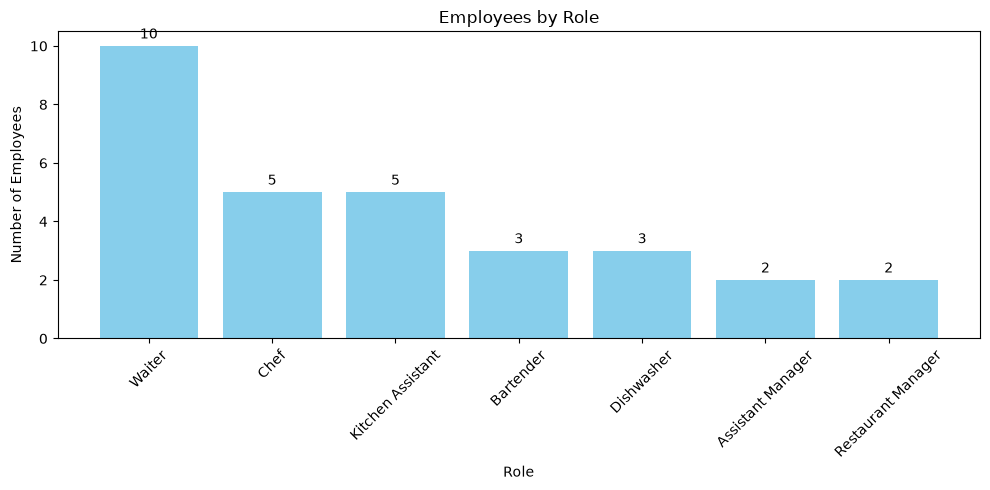

In [7]:
# ============================================================
# EMPLOYEES BY ROLE
# ============================================================

role_summary = (
    employees
    .groupby("role")
    .agg(
        employees=("employee_id", "count"),
        average_hourly_cost=("hourly_cost", "mean"),
        min_hourly_cost=("hourly_cost", "min"),
        max_hourly_cost=("hourly_cost", "max")
    )
    .reset_index()
    .sort_values("employees", ascending=False)
)

# ============================================================
# PLOT EMPLOYEES BY ROLE
# ============================================================
plt.figure(figsize=(10, 5))
bars = plt.bar(role_summary["role"], role_summary["employees"], color="skyblue")
plt.bar_label(bars, padding=3)
plt.xlabel("Role")
plt.ylabel("Number of Employees")
plt.title("Employees by Role")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Number of Employees by Employment Type')

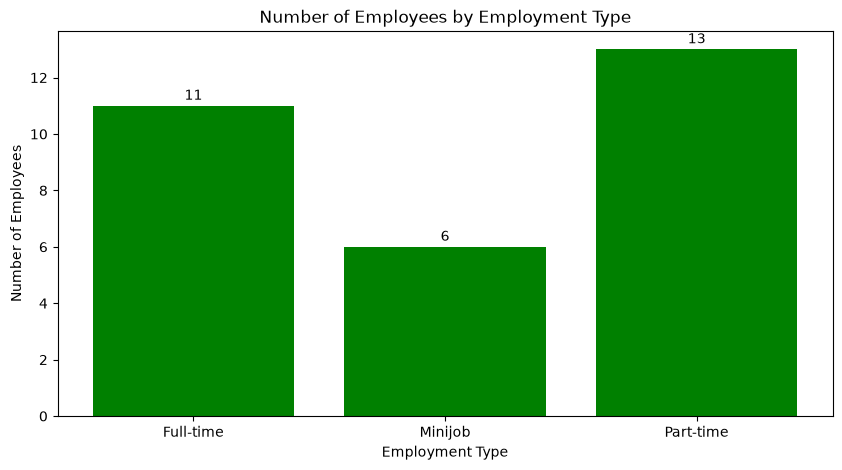

In [8]:
# ============================================================
# EMPLOYEES BY EMPLOYMENT TYPE
# ============================================================

employment_summary = (
    employees
    .groupby("employment_type")
    .agg(
        employees=("employee_id", "count"),
        average_hourly_cost=("hourly_cost", "mean")
    )
    .reset_index()
)

# ============================================================
# PLOT EMPLOYEES BY EMPLOYMENT TYPE
# ============================================================
plt.figure(figsize=(10, 5))
bars = plt.bar(employment_summary["employment_type"], employment_summary["employees"],color="green")
plt.xlabel("Employment Type")
plt.bar_label(bars, padding=2)
plt.ylabel("Number of Employees")
plt.title("Number of Employees by Employment Type")

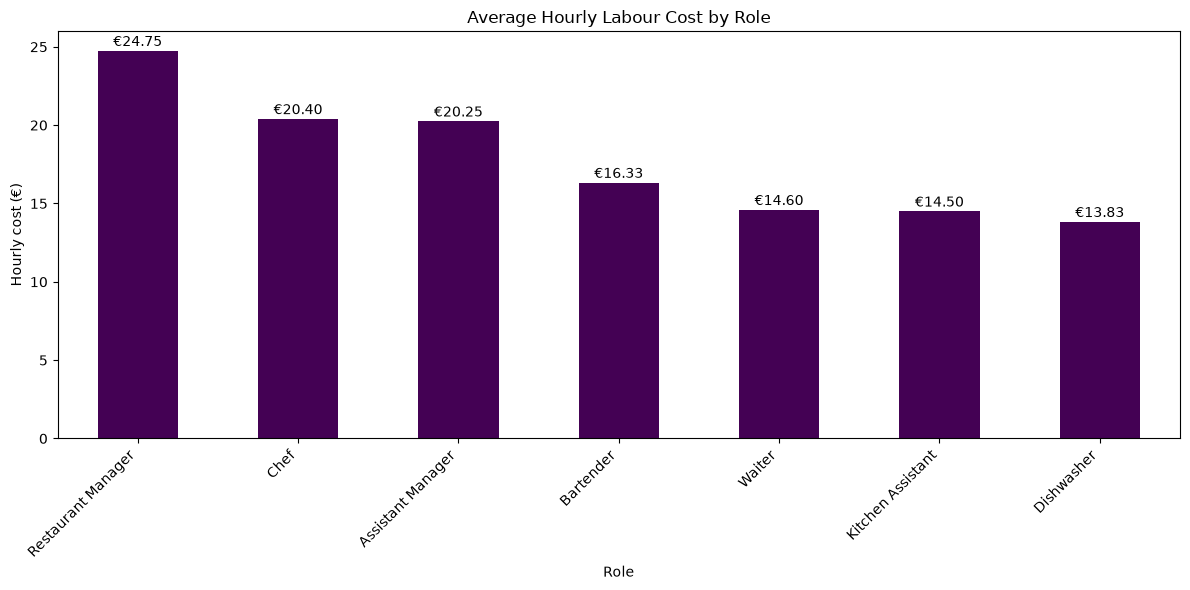

In [9]:
# ============================================================
# WORKFORCE COST STRUCTURE
# ============================================================

role_cost = ( employees .groupby("role")["hourly_cost"] .mean() .sort_values(ascending=False) )

plt.figure(figsize=(12, 6))

role_cost.plot(kind="bar", colormap="viridis")

plt.title("Average Hourly Labour Cost by Role")
plt.xlabel("Role")
plt.ylabel("Hourly cost (€)")
plt.xticks(rotation=45, ha="right")
plt.bar_label(plt.gca().containers[0], fmt="€%.2f", padding=1)
plt.tight_layout()
plt.show()

In [10]:
# ============================================================
# HISTORICAL SHIFT ANALYSIS
# ============================================================

daily_shifts = (
    shifts
    .groupby("shift_date")
    .agg(
        employees_scheduled=("employee_id", "nunique"),
        total_hours=("hours_worked", "sum"),
        labour_cost=("labour_cost", "sum")
    )
    .reset_index()
)

display( daily_shifts.head() )

,shift_date,employees_scheduled,total_hours,labour_cost
0,2024-01-01,10,63.50,"1,092.25"
1,2024-01-02,10,63.50,"1,048.50"
2,2024-01-03,9,57.00,998.75
3,2024-01-04,13,81.00,"1,300.00"
4,2024-01-05,13,81.00,"1,373.75"


In [11]:
# ============================================================
# HISTORICAL DAILY DEMAND
# ============================================================

daily_demand = (
    daily_model[
        ["date", "orders", "revenue", "average_order_value"]
    ]
    .copy()
)

daily_demand = daily_demand.rename( columns={"date": "shift_date"} )

display( daily_demand.head() )

,shift_date,orders,revenue,average_order_value
0,2024-01-01,40,"1,396.30",34.91
1,2024-01-02,56,"2,118.00",37.82
2,2024-01-03,50,"1,527.30",30.55
3,2024-01-04,67,"2,532.30",37.80
4,2024-01-05,91,"3,420.70",37.59


In [12]:
# ============================================================
# DEMAND + STAFFING DATASET
# ============================================================

historical_workforce = daily_demand.merge(
    daily_shifts,
    on="shift_date",
    how="left"
)
historical_workforce[
    [
        "employees_scheduled",
        "total_hours",
        "labour_cost"
    ]
] = historical_workforce[
    [
        "employees_scheduled",
        "total_hours",
        "labour_cost"
    ]
].fillna(0)

display(
    historical_workforce.head()
)

,shift_date,orders,revenue,average_order_value,employees_scheduled,total_hours,labour_cost
0,2024-01-01,40,"1,396.30",34.91,10,63.50,"1,092.25"
1,2024-01-02,56,"2,118.00",37.82,10,63.50,"1,048.50"
2,2024-01-03,50,"1,527.30",30.55,9,57.00,998.75
3,2024-01-04,67,"2,532.30",37.80,13,81.00,"1,300.00"
4,2024-01-05,91,"3,420.70",37.59,13,81.00,"1,373.75"


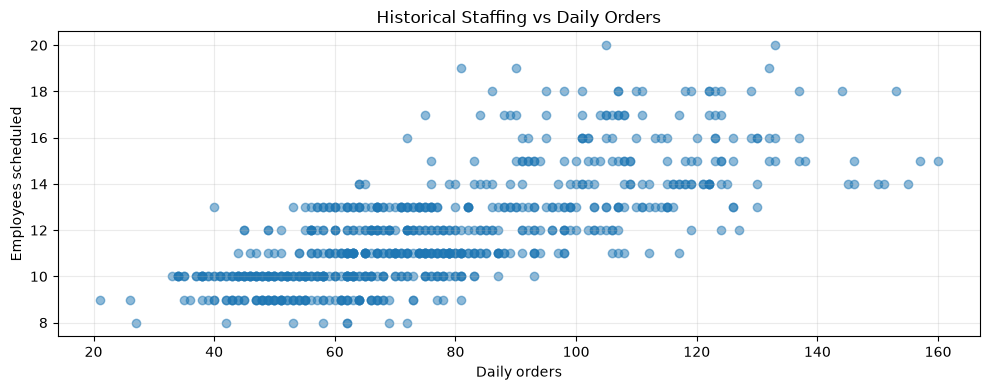

In [13]:
# ============================================================
# STAFFING RELATIONSHIP WITH DEMAND
# ============================================================

plt.figure(figsize=(10, 4))

plt.scatter(
    historical_workforce["orders"],
    historical_workforce["employees_scheduled"],
    alpha=0.5
)

plt.title("Historical Staffing vs Daily Orders")
plt.xlabel("Daily orders")
plt.ylabel("Employees scheduled")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

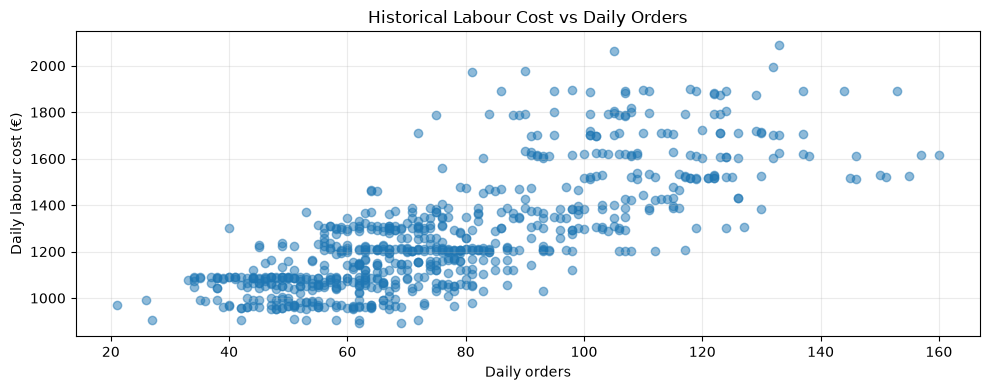

In [14]:
# ============================================================
# LABOUR COST VS DEMAND
# ============================================================

plt.figure(figsize=(10, 4))

plt.scatter(
    historical_workforce["orders"],
    historical_workforce["labour_cost"],
    alpha=0.5
)

plt.title("Historical Labour Cost vs Daily Orders")
plt.xlabel("Daily orders")
plt.ylabel("Daily labour cost (€)")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# HISTORICAL WORKFORCE KPIs
# ============================================================

total_orders = historical_workforce["orders"].sum()
total_hours = historical_workforce["total_hours"].sum()
total_labour_cost = historical_workforce["labour_cost"].sum()

avg_orders_per_day = historical_workforce["orders"].mean()
avg_staff_per_day = historical_workforce["employees_scheduled"].mean()
avg_labour_cost = historical_workforce["labour_cost"].mean()

orders_per_labour_hour = ( total_orders / total_hours if total_hours > 0 else np.nan )

labour_cost_per_order = ( total_labour_cost / total_orders if total_orders > 0 else np.nan )

workforce_kpis = pd.DataFrame({
    "KPI": [
        "Average daily orders",
        "Average employees scheduled per day",
        "Average daily labour cost",
        "Orders per labour hour",
        "Labour cost per order"
    ],
    "Value": [
        avg_orders_per_day,
        avg_staff_per_day,
        avg_labour_cost,
        orders_per_labour_hour,
        labour_cost_per_order
    ]
})

display(
    workforce_kpis.round(2)
)

,KPI,Value
0,Average daily orders,76.73
1,Average employees scheduled per day,11.90
2,Average daily labour cost,"1,263.26"
3,Orders per labour hour,1.03
4,Labour cost per order,16.46


In [16]:
# ============================================================
# DEMAND TIERS
# ============================================================

TIER_BOUNDS = [
    (60, "Low"),
    (101, "Standard"),
    (151, "High")
]


def demand_tier(orders):
    for bound, name in TIER_BOUNDS:
        if orders < bound:
            return name

    return "Very High"

historical_workforce["demand_tier"] = (
    historical_workforce["orders"]
    .apply(demand_tier)
)

display(
    historical_workforce[
        [
            "shift_date",
            "orders",
            "demand_tier",
            "employees_scheduled",
            "labour_cost"
        ]
    ].head(10)
)

,shift_date,orders,demand_tier,employees_scheduled,labour_cost
0,2024-01-01,40,Low,10,"1,092.25"
1,2024-01-02,56,Low,10,"1,048.50"
2,2024-01-03,50,Low,9,998.75
3,2024-01-04,67,Standard,13,"1,300.00"
4,2024-01-05,91,Standard,13,"1,373.75"
5,2024-01-06,103,High,13,"1,402.50"
6,2024-01-07,64,Standard,9,963.00
7,2024-01-08,34,Low,10,"1,091.25"
8,2024-01-09,55,Low,10,"1,049.00"
9,2024-01-10,47,Low,9,999.25


In [17]:
# ============================================================
# STAFFING REQUIREMENTS BY DEMAND TIER
# ============================================================

STAFFING_REQUIREMENTS = {
    "Low": [
        ("Restaurant Manager", "Full", 1),
        ("Chef", "Lunch", 1),
        ("Chef", "Dinner", 1),
        ("Kitchen Assistant", "Dinner", 1),
        ("Waiter", "Lunch", 2),
        ("Waiter", "Dinner", 2),
        ("Bartender", "Dinner", 1),
        ("Dishwasher", "Dinner", 1),
    ],

    "Standard": [
        ("Restaurant Manager", "Full", 1),
        ("Chef", "Lunch", 1),
        ("Chef", "Dinner", 2),
        ("Kitchen Assistant", "Lunch", 1),
        ("Kitchen Assistant", "Dinner", 1),
        ("Waiter", "Lunch", 2),
        ("Waiter", "Dinner", 3),
        ("Bartender", "Dinner", 1),
        ("Dishwasher", "Lunch", 1),
        ("Dishwasher", "Dinner", 1),
    ],

    "High": [
        ("Restaurant Manager", "Full", 1),
        ("Assistant Manager", "Dinner", 1),
        ("Chef", "Lunch", 1),
        ("Chef", "Dinner", 2),
        ("Kitchen Assistant", "Lunch", 1),
        ("Kitchen Assistant", "Dinner", 2),
        ("Waiter", "Lunch", 3),
        ("Waiter", "Dinner", 5),
        ("Bartender", "Dinner", 2),
        ("Dishwasher", "Lunch", 1),
        ("Dishwasher", "Dinner", 1),
    ],

    "Very High": [
        ("Restaurant Manager", "Full", 1),
        ("Assistant Manager", "Dinner", 1),
        ("Chef", "Lunch", 2),
        ("Chef", "Dinner", 2),
        ("Kitchen Assistant", "Lunch", 1),
        ("Kitchen Assistant", "Dinner", 2),
        ("Waiter", "Lunch", 4),
        ("Waiter", "Dinner", 6),
        ("Bartender", "Lunch", 1),
        ("Bartender", "Dinner", 2),
        ("Dishwasher", "Lunch", 1),
        ("Dishwasher", "Dinner", 2),
    ],
}

# ============================================================
# STAFFING REQUIREMENTS TABLE
# ============================================================

requirement_rows = []

for tier, requirements in STAFFING_REQUIREMENTS.items():
    for role, shift_type, count in requirements:
        requirement_rows.append({
            "Demand Tier": tier,
            "Role": role,
            "Shift": shift_type,
            "Required": count
        })
staffing_requirements_df = pd.DataFrame( requirement_rows )

display( staffing_requirements_df )

,Demand Tier,Role,Shift,Required
0,Low,Restaurant Manager,Full,1
1,Low,Chef,Lunch,1
2,Low,Chef,Dinner,1
3,Low,Kitchen Assistant,Dinner,1
4,Low,Waiter,Lunch,2
5,Low,Waiter,Dinner,2
6,Low,Bartender,Dinner,1
7,Low,Dishwasher,Dinner,1
8,Standard,Restaurant Manager,Full,1
9,Standard,Chef,Lunch,1


In [18]:
# ============================================================
# WORKFORCE EFFICIENCY
# ============================================================

historical_workforce["orders_per_labour_hour"] = (
    historical_workforce["orders"]
    / historical_workforce["total_hours"].replace(0, np.nan)
)

historical_workforce["labour_cost_per_order"] = (
    historical_workforce["labour_cost"]
    / historical_workforce["orders"].replace(0, np.nan)
)

display(
    historical_workforce[
        [
            "shift_date",
            "orders",
            "total_hours",
            "labour_cost",
            "orders_per_labour_hour",
            "labour_cost_per_order"
        ]
    ].head(10)
)

,shift_date,orders,total_hours,labour_cost,orders_per_labour_hour,labour_cost_per_order
0,2024-01-01,40,63.50,"1,092.25",0.63,27.31
1,2024-01-02,56,63.50,"1,048.50",0.88,18.72
2,2024-01-03,50,57.00,998.75,0.88,19.98
3,2024-01-04,67,81.00,"1,300.00",0.83,19.40
4,2024-01-05,91,81.00,"1,373.75",1.12,15.10
5,2024-01-06,103,81.00,"1,402.50",1.27,13.62
6,2024-01-07,64,57.00,963.00,1.12,15.05
7,2024-01-08,34,63.50,"1,091.25",0.54,32.10
8,2024-01-09,55,63.50,"1,049.00",0.87,19.07
9,2024-01-10,47,57.00,999.25,0.82,21.26


In [19]:
# ============================================================
# EFFICIENCY BY DEMAND TIER
# ============================================================

efficiency_by_tier = (
    historical_workforce
    .groupby("demand_tier")
    .agg(
        orders=("orders", "mean"),
        labour_hours=("total_hours", "mean"),
        labour_cost=("labour_cost", "mean"),
        orders_per_labour_hour=("orders_per_labour_hour", "mean"),
        labour_cost_per_order=("labour_cost_per_order", "mean")
    )
    .reindex(
        ["Low", "Standard", "High", "Very High"]
    )
    .reset_index()
)

display(
    efficiency_by_tier.round(2)
)

,demand_tier,orders,labour_hours,labour_cost,orders_per_labour_hour,labour_cost_per_order
0,Low,48.95,63.42,"1,073.23",0.78,22.45
1,Standard,75.61,72.88,"1,235.55",1.05,16.51
2,High,115.83,92.17,"1,591.88",1.28,13.84
3,Very High,155.20,93.30,"1,634.15",1.68,10.54


In [20]:
# ============================================================
# HISTORICAL STAFFING BY ROLE
# ============================================================

shift_role = shifts.merge(
    employees[
        [
            "employee_id",
            "role",
            "employment_type",
            "hourly_cost"
        ]
    ],
    on="employee_id",
    how="left"
)

role_shift_summary = (
    shift_role
    .groupby("role")
    .agg(
        shifts=("shift_id", "count"),
        employees=("employee_id", "nunique"),
        total_hours=("hours_worked", "sum"),
        labour_cost=("labour_cost", "sum")
    )
    .reset_index()
    .sort_values(
        "total_hours",
        ascending=False
    )
)

display(
    role_shift_summary.round(2)
)

,role,shifts,employees,total_hours,labour_cost
6,Waiter,3058,10,"18,257.00","271,568.25"
2,Chef,1798,5,"10,945.00","223,039.25"
4,Kitchen Assistant,1162,5,"7,054.00","103,787.25"
1,Bartender,880,3,"5,709.00","93,153.50"
3,Dishwasher,917,3,"5,444.50","76,110.75"
5,Restaurant Manager,495,2,"3,960.00","98,004.00"
0,Assistant Manager,386,2,"2,863.00","57,780.75"


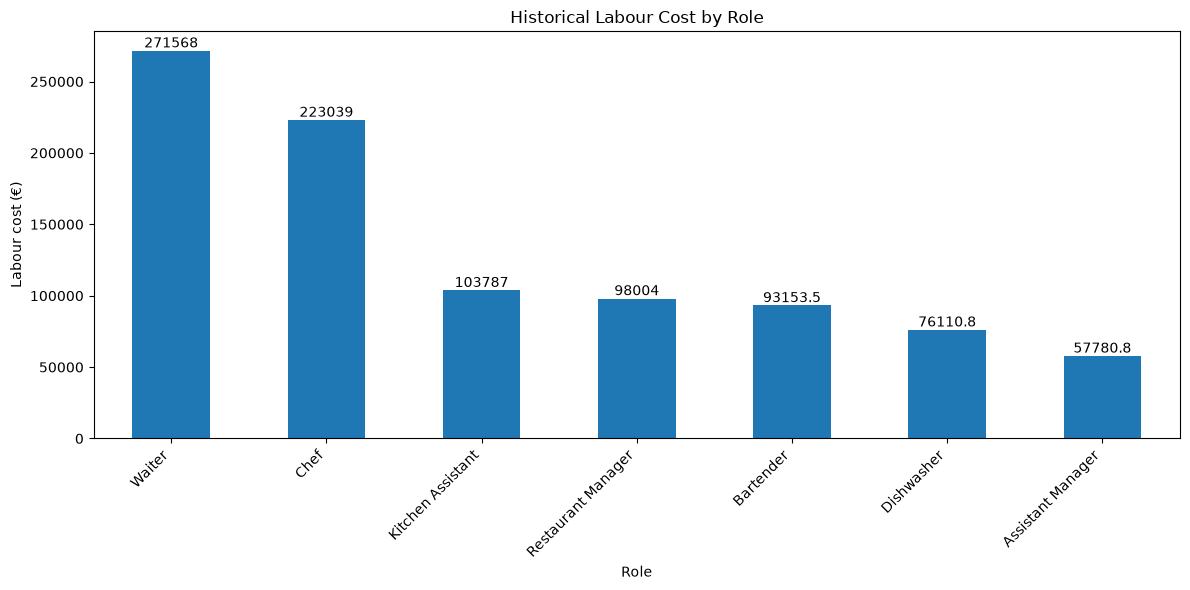

In [21]:
# ============================================================
# LABOUR COST BY ROLE
# ============================================================

plt.figure(figsize=(12, 6))

(
    role_shift_summary
    .set_index("role")["labour_cost"]
    .sort_values(ascending=False)
    .plot(kind="bar")
)

plt.title("Historical Labour Cost by Role")
plt.xlabel("Role")
plt.ylabel("Labour cost (€)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.bar_label(plt.gca().containers[0], label_type="edge")
plt.show()

In [22]:
# ============================================================
# EMPLOYEE AVAILABILITY ANALYSIS
# ============================================================

availability_summary = (
    availability
    .groupby("availability_status")
    .agg(
        employee_days=("employee_id", "count"),
        average_max_hours=("max_hours", "mean")
    )
    .reset_index()
)

display(
    availability_summary.round(2)
)

,availability_status,employee_days,average_max_hours
0,Available,147,7.06
1,Limited,9,5.50
2,Unavailable,54,0.00


In [23]:
# ============================================================
# AVAILABILITY BY ROLE
# ============================================================

availability_role = availability.merge(
    employees[
        ["employee_id", "role", "employment_type"]
    ],
    on="employee_id",
    how="left"
)

availability_by_role = (
    availability_role
    .groupby(
        ["role", "availability_status"]
    )
    .size()
    .reset_index(
        name="employee_days"
    )
)

display(
    availability_by_role
)

,role,availability_status,employee_days
0,Assistant Manager,Available,10
1,Assistant Manager,Unavailable,4
2,Bartender,Available,14
3,Bartender,Limited,1
4,Bartender,Unavailable,6
5,Chef,Available,25
6,Chef,Unavailable,10
7,Dishwasher,Available,15
8,Dishwasher,Limited,3
9,Dishwasher,Unavailable,3


In [24]:
# ============================================================
# CONTRACT HOUR LIMITS
# ============================================================

WEEKLY_HOUR_CAP = {
    "Full-time": 40.0,
    "Part-time": 30.0,
    "Minijob": 12.0
}

employees["weekly_hour_cap"] = (
    employees["employment_type"]
    .map(WEEKLY_HOUR_CAP)
)

display(
    employees[
        [
            "employee_id",
            "role",
            "employment_type",
            "hourly_cost",
            "weekly_hour_cap"
        ]
    ].head(15)
)

,employee_id,role,employment_type,hourly_cost,weekly_hour_cap
0,E001,Restaurant Manager,Full-time,25.00,40.00
1,E002,Restaurant Manager,Full-time,24.50,40.00
2,E003,Assistant Manager,Full-time,21.00,40.00
3,E004,Assistant Manager,Full-time,19.50,40.00
4,E005,Chef,Full-time,20.50,40.00
5,E006,Chef,Full-time,20.50,40.00
6,E007,Chef,Full-time,20.50,40.00
7,E008,Chef,Part-time,19.50,30.00
8,E009,Chef,Part-time,21.00,30.00
9,E010,Kitchen Assistant,Part-time,15.00,30.00


In [25]:
# ============================================================
# HISTORICAL WEEKLY HOURS
# ============================================================

shift_role["iso_year"] = (
    shift_role["shift_date"]
    .dt.isocalendar()
    .year
)

shift_role["iso_week"] = (
    shift_role["shift_date"]
    .dt.isocalendar()
    .week
)

weekly_hours = (
    shift_role
    .groupby(
        [
            "employee_id",
            "iso_year",
            "iso_week"
        ]
    )
    .agg(
        hours_worked=("hours_worked", "sum"),
        labour_cost=("labour_cost", "sum")
    )
    .reset_index()
)

weekly_hours = weekly_hours.merge(
    employees[
        [
            "employee_id",
            "employment_type",
            "weekly_hour_cap"
        ]
    ],
    on="employee_id",
    how="left"
)

weekly_hours["hours_remaining"] = (
    weekly_hours["weekly_hour_cap"]
    - weekly_hours["hours_worked"]
)

display(
    weekly_hours.head(15)
)

,employee_id,iso_year,iso_week,hours_worked,labour_cost,employment_type,weekly_hour_cap,hours_remaining
0,E001,2024,1,16.00,400.00,Full-time,40.00,24.00
1,E001,2024,2,16.00,400.00,Full-time,40.00,24.00
2,E001,2024,3,24.00,600.00,Full-time,40.00,16.00
3,E001,2024,4,16.00,400.00,Full-time,40.00,24.00
4,E001,2024,5,24.00,600.00,Full-time,40.00,16.00
5,E001,2024,6,16.00,400.00,Full-time,40.00,24.00
6,E001,2024,7,16.00,400.00,Full-time,40.00,24.00
7,E001,2024,8,24.00,600.00,Full-time,40.00,16.00
8,E001,2024,9,16.00,400.00,Full-time,40.00,24.00
9,E001,2024,10,24.00,600.00,Full-time,40.00,16.00


In [26]:
# ============================================================
# WEEKLY HOUR COMPLIANCE
# ============================================================

weekly_hours["within_contract_limit"] = (
    weekly_hours["hours_worked"]
    <= weekly_hours["weekly_hour_cap"]
)

print(
    "Weeks within contract limit:",
    weekly_hours["within_contract_limit"].mean() * 100,
    "%"
)

print(
    "Maximum weekly hours recorded:",
    weekly_hours["hours_worked"].max()
)

Weeks within contract limit: 100.0 %
Maximum weekly hours recorded: 32.5


# 4. Forecast Input

In [27]:
# ============================================================
# REVENUE FORECAST INPUT
# ============================================================

# The planning window comes from the revenue forecast file loaded in the next step
# (notebook 02: forecast_next_14_days). It must not be derived from the history end date,
# because the history ends 2025-12-31 while the operational forecast starts today.

forecast_path = OUTPUT_DIR / "revenue_forecast_next_14_days.csv"

revenue_forecast = pd.read_csv(
    forecast_path,
    parse_dates=["date"]
).sort_values("date").reset_index(drop=True)

required_columns = {"date", "forecast_revenue"}
missing_columns = required_columns - set(revenue_forecast.columns)
if missing_columns:
    raise ValueError(
        f"Revenue forecast is missing columns: {sorted(missing_columns)}"
    )

if revenue_forecast["date"].duplicated().any():
    raise ValueError("Revenue forecast contains duplicate dates.")

if revenue_forecast["forecast_revenue"].isna().any():
    raise ValueError("Revenue forecast contains missing revenue values.")

print("Using the selected Prophet revenue forecast from Notebook 02.")
print(
    "Forecast period:",
    revenue_forecast["date"].min().date(),
    "to",
    revenue_forecast["date"].max().date()
)
print("Number of forecast days:", len(revenue_forecast))

display(revenue_forecast.head())


Using the selected Prophet revenue forecast from Notebook 02.
Forecast period: 2026-11-03 to 2026-11-16
Number of forecast days: 14


,date,forecast_revenue,lower_bound,upper_bound
0,2026-11-03,"2,359.81","1,789.10","2,977.77"
1,2026-11-04,"2,442.00","1,837.95","3,019.95"
2,2026-11-05,"2,916.28","2,277.98","3,480.15"
3,2026-11-06,"4,302.56","3,719.45","4,860.27"
4,2026-11-07,"4,965.01","4,317.53","5,542.98"


In [28]:
# ============================================================
# WORKFORCE FORECAST HORIZON
# ============================================================

forecast_dates = pd.DatetimeIndex(revenue_forecast["date"])
FORECAST_HORIZON = len(forecast_dates)

if FORECAST_HORIZON == 0:
    raise ValueError("Revenue forecast contains no planning dates.")

expected_dates = pd.date_range(
    start=forecast_dates.min(),
    periods=FORECAST_HORIZON,
    freq="D"
)

if not forecast_dates.equals(expected_dates):
    raise ValueError("Revenue forecast dates must be consecutive daily dates.")

print("Planning horizon:", FORECAST_HORIZON, "days")
print("Workforce planning starts:", forecast_dates.min().date())
print("Workforce planning ends:", forecast_dates.max().date())


Planning horizon: 14 days
Workforce planning starts: 2026-11-03
Workforce planning ends: 2026-11-16


In [29]:
# ============================================================
# FORECAST REVENUE → EXPECTED ORDERS
# ============================================================

historical_aov = (
    daily_model["revenue"]
    / daily_model["orders"].replace(0, np.nan)
).replace(
    [np.inf, -np.inf],
    np.nan
).median()

revenue_forecast["expected_orders"] = (
    revenue_forecast["forecast_revenue"]
    / historical_aov
).round().astype(int)

print(
    f"Historical median average order value: "
    f"€{historical_aov:.2f}"
)

display(
    revenue_forecast[
        [
            "date",
            "forecast_revenue",
            "expected_orders"
        ]
    ].round(2)
)

Historical median average order value: €36.42


/var/folders/lk/_pf4928d6_x99xld7btjlldc0000gn/T/ipykernel_4499/297541434.py:30: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,date,forecast_revenue,expected_orders
0,2026-11-03,"2,359.81",65
1,2026-11-04,"2,442.00",67
2,2026-11-05,"2,916.28",80
3,2026-11-06,"4,302.56",118
4,2026-11-07,"4,965.01",136
5,2026-11-08,"2,931.71",81
6,2026-11-09,"2,035.82",56
7,2026-11-10,"2,361.15",65
8,2026-11-11,"2,298.62",63
9,2026-11-12,"2,848.73",78


In [30]:
# ============================================================
# FORECAST DEMAND FEATURES
# ============================================================

revenue_forecast["day_of_week"] = (
    revenue_forecast["date"]
    .dt.day_name()
)

revenue_forecast["is_weekend"] = (
    revenue_forecast["date"]
    .dt.dayofweek >= 5
).astype(int)

revenue_forecast["demand_tier"] = (
    revenue_forecast["expected_orders"]
    .apply(demand_tier)
)

display(
    revenue_forecast[
        [
            "date",
            "day_of_week",
            "forecast_revenue",
            "expected_orders",
            "demand_tier"
        ]
    ]
)

,date,day_of_week,forecast_revenue,expected_orders,demand_tier
0,2026-11-03,Tuesday,"2,359.81",65,Standard
1,2026-11-04,Wednesday,"2,442.00",67,Standard
2,2026-11-05,Thursday,"2,916.28",80,Standard
3,2026-11-06,Friday,"4,302.56",118,High
4,2026-11-07,Saturday,"4,965.01",136,High
5,2026-11-08,Sunday,"2,931.71",81,Standard
6,2026-11-09,Monday,"2,035.82",56,Low
7,2026-11-10,Tuesday,"2,361.15",65,Standard
8,2026-11-11,Wednesday,"2,298.62",63,Standard
9,2026-11-12,Thursday,"2,848.73",78,Standard


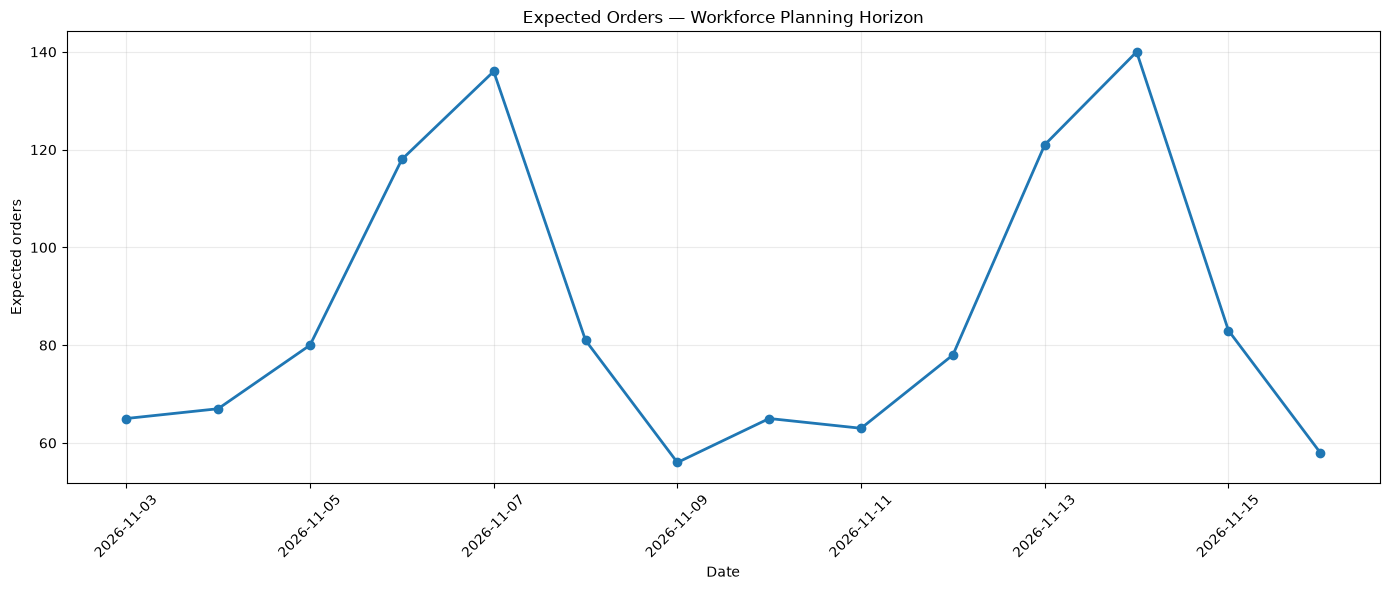

In [31]:
# ============================================================
# FORECASTED ORDERS
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    revenue_forecast["date"],
    revenue_forecast["expected_orders"],
    marker="o",
    linewidth=2
)

plt.title(
    "Expected Orders — Workforce Planning Horizon"
)

plt.xlabel("Date")
plt.ylabel("Expected orders")

plt.xticks(rotation=45)
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [32]:
# ============================================================
# FORECAST STAFFING REQUIREMENTS
# ============================================================

def get_staffing_requirements(orders):

    tier = demand_tier(orders)

    rows = []

    for role, shift_type, count in STAFFING_REQUIREMENTS[tier]:

        rows.append({
            "role": role,
            "shift_type": shift_type,
            "required": count
        })

    return pd.DataFrame(rows)

# ============================================================
# BUILD FORECAST STAFFING TABLE
# ============================================================

forecast_staffing_rows = []

for _, row in revenue_forecast.iterrows():

    requirements = get_staffing_requirements(
        row["expected_orders"]
    )

    for _, requirement in requirements.iterrows():

        forecast_staffing_rows.append({
            "date": row["date"],
            "expected_orders": row["expected_orders"],
            "demand_tier": row["demand_tier"],
            "role": requirement["role"],
            "shift_type": requirement["shift_type"],
            "required": requirement["required"]
        })

forecast_staffing = pd.DataFrame(
    forecast_staffing_rows
)

display(
    forecast_staffing.head()
)

,date,expected_orders,demand_tier,role,shift_type,required
0,2026-11-03,65,Standard,Restaurant Manager,Full,1
1,2026-11-03,65,Standard,Chef,Lunch,1
2,2026-11-03,65,Standard,Chef,Dinner,2
3,2026-11-03,65,Standard,Kitchen Assistant,Lunch,1
4,2026-11-03,65,Standard,Kitchen Assistant,Dinner,1


In [33]:
# ============================================================
# DAILY STAFFING REQUIREMENT
# ============================================================

daily_required_staff = (
    forecast_staffing
    .groupby("date")
    .agg(
        expected_orders=("expected_orders", "first"),
        demand_tier=("demand_tier", "first"),
        required_staff=("required", "sum")
    )
    .reset_index()
)

display(
    daily_required_staff
)

,date,expected_orders,demand_tier,required_staff
0,2026-11-03,65,Standard,14
1,2026-11-04,67,Standard,14
2,2026-11-05,80,Standard,14
3,2026-11-06,118,High,20
4,2026-11-07,136,High,20
5,2026-11-08,81,Standard,14
6,2026-11-09,56,Low,10
7,2026-11-10,65,Standard,14
8,2026-11-11,63,Standard,14
9,2026-11-12,78,Standard,14


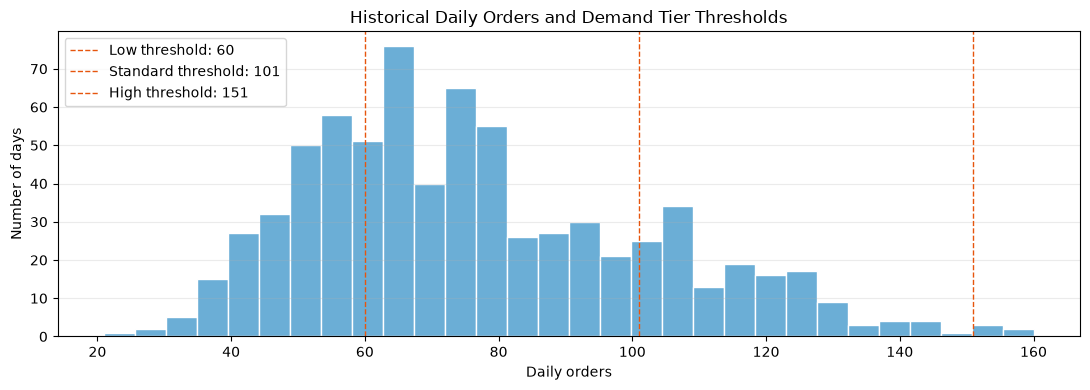

In [34]:
# ============================================================
# HISTORICAL DAILY ORDERS AND DEMAND TIERS
# ============================================================

plt.figure(figsize=(11, 4))

plt.hist(
    daily_model["orders"],
    bins=30,
    color="#6baed6",
    edgecolor="white"
)

for bound, tier_name in TIER_BOUNDS:
    plt.axvline(
        bound,
        color="#e6550d",
        linestyle="--",
        linewidth=1,
        label=f"{tier_name} threshold: {bound}"
    )

plt.title("Historical Daily Orders and Demand Tier Thresholds")
plt.xlabel("Daily orders")
plt.ylabel("Number of days")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

Employee Eligibility Function
Now we move from how many people we need to which employees can actually work.

The eligibility logic respects:
- employment dates
- availability
- maximum daily hours
- weekly contractual hours
These are also the constraints used in the original dataset generation.

In [35]:
# ============================================================
# EMPLOYEE ELIGIBILITY AND INELIGIBILITY REASONS
# ============================================================

SHIFT_DEFINITIONS = {
    "Lunch": {"start": "10:30", "end": "16:00", "hours": 5.5},
    "Dinner": {"start": "16:30", "end": "23:00", "hours": 6.5},
    "Full": {"start": "11:30", "end": "20:00", "hours": 8.0}
}

MAX_DAILY_HOURS = 10.0


def employee_ineligibility_reason(
    employee,
    availability_row,
    date,
    shift_hours,
    weekly_hours_used,
    already_scheduled_today,
    daily_hours_used
):
    """Return the first existing roster constraint an employee fails."""

    if date < employee["employment_start"]:
        return "not employed yet"

    if (
        pd.notna(employee["employment_end"])
        and date > employee["employment_end"]
    ):
        return "employment ended"

    # A person can work no more than one shift on a calendar day.
    if already_scheduled_today:
        return "already working that day"

    if daily_hours_used + shift_hours > MAX_DAILY_HOURS:
        return "daily hour cap reached"

    if availability_row is None:
        return "availability record missing"

    if availability_row.availability_status == "Unavailable":
        return "unavailable that weekday"

    if availability_row.max_hours < shift_hours:
        return "insufficient daily hours"

    if weekly_hours_used + shift_hours > employee["weekly_hour_cap"]:
        return "weekly hour cap reached"

    return None


Build Forecast Roster

In [36]:
# ============================================================
# BUILD FORECAST ROSTER AND EXPLAIN GAPS
# ============================================================

def build_forecast_roster(forecast_staffing, employees, availability):
    employees_local = employees.copy()
    availability_local = availability.copy()

    employees_local["weekly_hour_cap"] = (
        employees_local["employment_type"].map(WEEKLY_HOUR_CAP)
    )

    # Availability convention: Monday=1 through Sunday=7.
    availability_lookup = {
        (row.employee_id, int(row.day_of_week_num)): row
        for row in availability_local.itertuples(index=False)
    }

    weekly_hours_used = defaultdict(float)
    daily_hours_used = defaultdict(float)
    scheduled_dates = set()
    roster_rows = []
    gap_rows = []

    for _, requirement in forecast_staffing.iterrows():
        date = pd.Timestamp(requirement["date"])
        role = requirement["role"]
        shift_type = requirement["shift_type"]
        required_count = int(requirement["required"])
        shift_info = SHIFT_DEFINITIONS[shift_type]
        shift_hours = shift_info["hours"]

        weekday_key = date.dayofweek + 1
        iso = date.isocalendar()
        role_employees = employees_local[employees_local["role"] == role]
        candidates = []
        reason_counts = {}

        for _, employee in role_employees.iterrows():
            employee_id = employee["employee_id"]
            employee_date_key = (employee_id, date.date())
            week_key = (employee_id, int(iso.year), int(iso.week))
            availability_row = availability_lookup.get(
                (employee_id, weekday_key)
            )

            reason = employee_ineligibility_reason(
                employee=employee,
                availability_row=availability_row,
                date=date,
                shift_hours=shift_hours,
                weekly_hours_used=weekly_hours_used[week_key],
                already_scheduled_today=(employee_date_key in scheduled_dates),
                daily_hours_used=daily_hours_used[employee_date_key]
            )

            if reason is None:
                candidates.append((employee, weekly_hours_used[week_key]))
            else:
                reason_counts[reason] = reason_counts.get(reason, 0) + 1

        # Preserve the current selection policy: prioritize employees
        # with the fewest hours already assigned in the ISO week.
        candidates.sort(key=lambda item: item[1])
        selected = candidates[:required_count]

        for employee, _ in selected:
            employee_id = employee["employee_id"]
            employee_date_key = (employee_id, date.date())
            week_key = (employee_id, int(iso.year), int(iso.week))

            weekly_hours_used[week_key] += shift_hours
            daily_hours_used[employee_date_key] += shift_hours
            scheduled_dates.add(employee_date_key)

            roster_rows.append({
                "date": date,
                "role": role,
                "shift_type": shift_type,
                "employee_id": employee_id,
                "employee_name": employee["employee_name"],
                "employment_type": employee["employment_type"],
                "start_time": shift_info["start"],
                "end_time": shift_info["end"],
                "hours": shift_hours,
                "hourly_cost": employee["hourly_cost"],
                "labour_cost": shift_hours * employee["hourly_cost"]
            })

        unfilled_count = required_count - len(selected)
        if unfilled_count > 0:
            reason_parts = []

            if role_employees.empty:
                reason_parts.append("no employees with this role")
            elif candidates:
                reason_parts.append(
                    f"only {len(candidates)} eligible employee(s) "
                    f"for {required_count} required position(s)"
                )

            reason_parts.extend(
                f"{reason} ({count} employee(s))"
                for reason, count in reason_counts.items()
            )

            gap_rows.append({
                "date": date,
                "weekday": date.day_name(),
                "role": role,
                "shift_type": shift_type,
                "hours": shift_hours,
                "required": required_count,
                "assigned": len(selected),
                "unfilled": unfilled_count,
                "reason": "; ".join(reason_parts)
            })

    return pd.DataFrame(roster_rows), pd.DataFrame(gap_rows)


In [37]:
# ============================================================
# GENERATE RECOMMENDED ROSTER AND STAFFING GAPS
# ============================================================

recommended_roster, staffing_gaps = build_forecast_roster(
    forecast_staffing,
    employees,
    availability
)

print("Recommended shift positions filled:", len(recommended_roster))
print("Unfilled staffing requirements:", int(staffing_gaps["unfilled"].sum()) if not staffing_gaps.empty else 0)
print("Employees assigned more than one shift on any date:", int(recommended_roster.duplicated(["date", "employee_id"]).sum()))


Recommended shift positions filled: 183
Unfilled staffing requirements: 29
Employees assigned more than one shift on any date: 0


In [38]:
# ============================================================
# UNCOVERED POSITIONS AND REASONS
# ============================================================

if staffing_gaps.empty:
    print("All required staffing positions are covered.")
else:
    display(
        staffing_gaps[
            [
                "date",
                "weekday",
                "role",
                "shift_type",
                "hours",
                "required",
                "assigned",
                "unfilled",
                "reason"
            ]
        ].sort_values(
            ["date", "role", "shift_type"]
        ).reset_index(drop=True)
    )

,date,weekday,role,shift_type,hours,required,assigned,unfilled,reason
0,2026-11-03,Tuesday,Chef,Dinner,6.50,2,1,1,only 1 eligible employee(s) for 2 required pos...
1,2026-11-04,Wednesday,Waiter,Dinner,6.50,3,2,1,only 2 eligible employee(s) for 3 required pos...
2,2026-11-05,Thursday,Dishwasher,Dinner,6.50,1,0,1,unavailable that weekday (1 employee(s)); alre...
3,2026-11-05,Thursday,Kitchen Assistant,Dinner,6.50,1,0,1,already working that day (1 employee(s)); unav...
4,2026-11-06,Friday,Kitchen Assistant,Dinner,6.50,2,0,2,unavailable that weekday (2 employee(s)); alre...
5,2026-11-06,Friday,Waiter,Dinner,6.50,5,4,1,only 4 eligible employee(s) for 5 required pos...
6,2026-11-07,Saturday,Dishwasher,Dinner,6.50,1,0,1,already working that day (1 employee(s)); insu...
7,2026-11-07,Saturday,Waiter,Dinner,6.50,5,4,1,only 4 eligible employee(s) for 5 required pos...
8,2026-11-08,Sunday,Dishwasher,Dinner,6.50,1,0,1,already working that day (1 employee(s)); week...
9,2026-11-08,Sunday,Waiter,Dinner,6.50,3,1,2,only 1 eligible employee(s) for 3 required pos...


Check Whether Requirements Were Fully Covered.

A staffing recommendation is not useful if we simply assume every required employee is available.

In [39]:
# ============================================================
# STAFFING COVERAGE CHECK
# ============================================================

assigned_staffing = (recommended_roster.groupby(["date", "role", "shift_type"])
    .size()
    .reset_index(
        name="assigned"
    )
)

staffing_coverage = forecast_staffing.merge(
    assigned_staffing,
    on=[
        "date",
        "role",
        "shift_type"
    ],
    how="left"
)

staffing_coverage["assigned"] = (
    staffing_coverage["assigned"]
    .fillna(0)
)

staffing_coverage["shortfall"] = (
    staffing_coverage["required"]
    - staffing_coverage["assigned"]
)

staffing_coverage["coverage_status"] = np.where(
    staffing_coverage["shortfall"] > 0,
    "Under-covered",
    "Covered"
)

display(
    staffing_coverage
)

,date,expected_orders,demand_tier,role,shift_type,required,assigned,shortfall,coverage_status
0,2026-11-03,65,Standard,Restaurant Manager,Full,1,1.00,0.00,Covered
1,2026-11-03,65,Standard,Chef,Lunch,1,1.00,0.00,Covered
2,2026-11-03,65,Standard,Chef,Dinner,2,1.00,1.00,Under-covered
3,2026-11-03,65,Standard,Kitchen Assistant,Lunch,1,1.00,0.00,Covered
4,2026-11-03,65,Standard,Kitchen Assistant,Dinner,1,1.00,0.00,Covered
...,...,...,...,...,...,...,...,...,...
135,2026-11-16,58,Low,Kitchen Assistant,Dinner,1,1.00,0.00,Covered
136,2026-11-16,58,Low,Waiter,Lunch,2,2.00,0.00,Covered
137,2026-11-16,58,Low,Waiter,Dinner,2,2.00,0.00,Covered
138,2026-11-16,58,Low,Bartender,Dinner,1,1.00,0.00,Covered


In [40]:
# ============================================================
# STAFFING COVERAGE SUMMARY
# ============================================================

coverage_summary = (
    staffing_coverage
    .groupby("coverage_status")
    .size()
    .reset_index(
        name="requirements"
    )
)

display(
    coverage_summary
)

,coverage_status,requirements
0,Covered,119
1,Under-covered,21


In [41]:
# ============================================================
# FORECAST LABOUR COST
# ============================================================

daily_forecast_labour = (
    recommended_roster
    .groupby("date")
    .agg(
        scheduled_employees=(
            "employee_id",
            "nunique"
        ),
        labour_hours=(
            "hours",
            "sum"
        ),
        labour_cost=(
            "labour_cost",
            "sum"
        )
    )
    .reset_index()
)

display(
    daily_forecast_labour.round(2)
)

/var/folders/lk/_pf4928d6_x99xld7btjlldc0000gn/T/ipykernel_4499/3021050035.py:26: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  daily_forecast_labour.round(2)


,date,scheduled_employees,labour_hours,labour_cost
0,2026-11-03,13,81.00,"1,350.50"
1,2026-11-04,13,81.00,"1,366.75"
2,2026-11-05,12,74.50,"1,303.00"
3,2026-11-06,17,106.00,"1,803.50"
4,2026-11-07,18,112.50,"1,891.00"
5,2026-11-08,11,68.00,"1,199.75"
6,2026-11-09,9,57.00,964.00
7,2026-11-10,13,81.00,"1,338.00"
8,2026-11-11,12,74.50,"1,279.00"
9,2026-11-12,13,81.00,"1,392.25"


Combine Revenue, Orders, Staffing and Cost

In [42]:
# ============================================================
# FINAL WORKFORCE FORECAST TABLE
# ============================================================

workforce_forecast = (
    daily_required_staff
    .merge(
        daily_forecast_labour,
        on="date",
        how="left"
    )
)

workforce_forecast["labour_cost"] = (
    workforce_forecast["labour_cost"]
    .fillna(0)
)

workforce_forecast["labour_hours"] = (
    workforce_forecast["labour_hours"]
    .fillna(0)
)

workforce_forecast["scheduled_employees"] = (
    workforce_forecast[
        "scheduled_employees"
    ]
    .fillna(0)
)

workforce_forecast = workforce_forecast.merge(
    revenue_forecast[
        [
            "date",
            "forecast_revenue"
        ]
    ],
    on="date",
    how="left"
)

workforce_forecast[
    "labour_cost_pct_revenue"
] = (
    workforce_forecast["labour_cost"]
    / workforce_forecast["forecast_revenue"]
    * 100
)

workforce_forecast[
    "forecast_orders_per_labour_hour"
] = (
    workforce_forecast["expected_orders"]
    / workforce_forecast["labour_hours"]
    .replace(0, np.nan)
)

display(
    workforce_forecast.round(2)
)

/var/folders/lk/_pf4928d6_x99xld7btjlldc0000gn/T/ipykernel_4499/1382597557.py:59: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  workforce_forecast.round(2)


,date,expected_orders,demand_tier,required_staff,scheduled_employees,labour_hours,labour_cost,forecast_revenue,labour_cost_pct_revenue,forecast_orders_per_labour_hour
0,2026-11-03,65,Standard,14,13,81.00,"1,350.50","2,359.81",57.23,0.80
1,2026-11-04,67,Standard,14,13,81.00,"1,366.75","2,442.00",55.97,0.83
2,2026-11-05,80,Standard,14,12,74.50,"1,303.00","2,916.28",44.68,1.07
3,2026-11-06,118,High,20,17,106.00,"1,803.50","4,302.56",41.92,1.11
4,2026-11-07,136,High,20,18,112.50,"1,891.00","4,965.01",38.09,1.21
5,2026-11-08,81,Standard,14,11,68.00,"1,199.75","2,931.71",40.92,1.19
6,2026-11-09,56,Low,10,9,57.00,964.00,"2,035.82",47.35,0.98
7,2026-11-10,65,Standard,14,13,81.00,"1,338.00","2,361.15",56.67,0.80
8,2026-11-11,63,Standard,14,12,74.50,"1,279.00","2,298.62",55.64,0.85
9,2026-11-12,78,Standard,14,13,81.00,"1,392.25","2,848.73",48.87,0.96


In [43]:
# ============================================================
# FORECAST WORKFORCE KPIs
# ============================================================

forecast_total_revenue = (
    workforce_forecast[
        "forecast_revenue"
    ].sum()
)

forecast_total_orders = (
    workforce_forecast[
        "expected_orders"
    ].sum()
)

forecast_labour_cost = (
    workforce_forecast[
        "labour_cost"
    ].sum()
)

forecast_labour_hours = (
    workforce_forecast[
        "labour_hours"
    ].sum()
)

forecast_labour_cost_pct = (
    forecast_labour_cost
    / forecast_total_revenue
    * 100
)

forecast_orders_per_labour_hour = (
    forecast_total_orders
    / forecast_labour_hours
)

forecast_labour_cost_per_order = (
    forecast_labour_cost
    / forecast_total_orders
)

forecast_kpis = pd.DataFrame({
    "KPI": [
        "Forecast revenue",
        "Expected orders",
        "Labour hours",
        "Labour cost",
        "Labour cost as % of revenue",
        "Orders per labour hour",
        "Labour cost per order"
    ],
    "Value": [
        forecast_total_revenue,
        forecast_total_orders,
        forecast_labour_hours,
        forecast_labour_cost,
        forecast_labour_cost_pct,
        forecast_orders_per_labour_hour,
        forecast_labour_cost_per_order
    ]
})

display(
    forecast_kpis.round(2)
)

,KPI,Value
0,Forecast revenue,"44,111.13"
1,Expected orders,"1,211.00"
2,Labour hours,"1,140.50"
3,Labour cost,"19,467.00"
4,Labour cost as % of revenue,44.13
5,Orders per labour hour,1.06
6,Labour cost per order,16.08


In [44]:
# ============================================================
# RECOMMENDED STAFF BY ROLE
# ============================================================

recommended_by_role = (
    recommended_roster
    .groupby("role")
    .agg(
        employees=(
            "employee_id",
            "nunique"
        ),
        shifts=(
            "employee_id",
            "count"
        ),
        hours=(
            "hours",
            "sum"
        ),
        labour_cost=(
            "labour_cost",
            "sum"
        )
    )
    .reset_index()
    .sort_values(
        "hours",
        ascending=False
    )
)

display(
    recommended_by_role.round(2)
)

,role,employees,shifts,hours,labour_cost
6,Waiter,9,67,403.50,"5,969.50"
2,Chef,4,36,220.00,"4,529.50"
4,Kitchen Assistant,4,25,150.50,"2,197.50"
1,Bartender,3,18,117.00,"1,911.00"
5,Restaurant Manager,2,14,112.00,"2,772.00"
3,Dishwasher,2,19,111.50,"1,561.00"
0,Assistant Manager,2,4,26.00,526.50


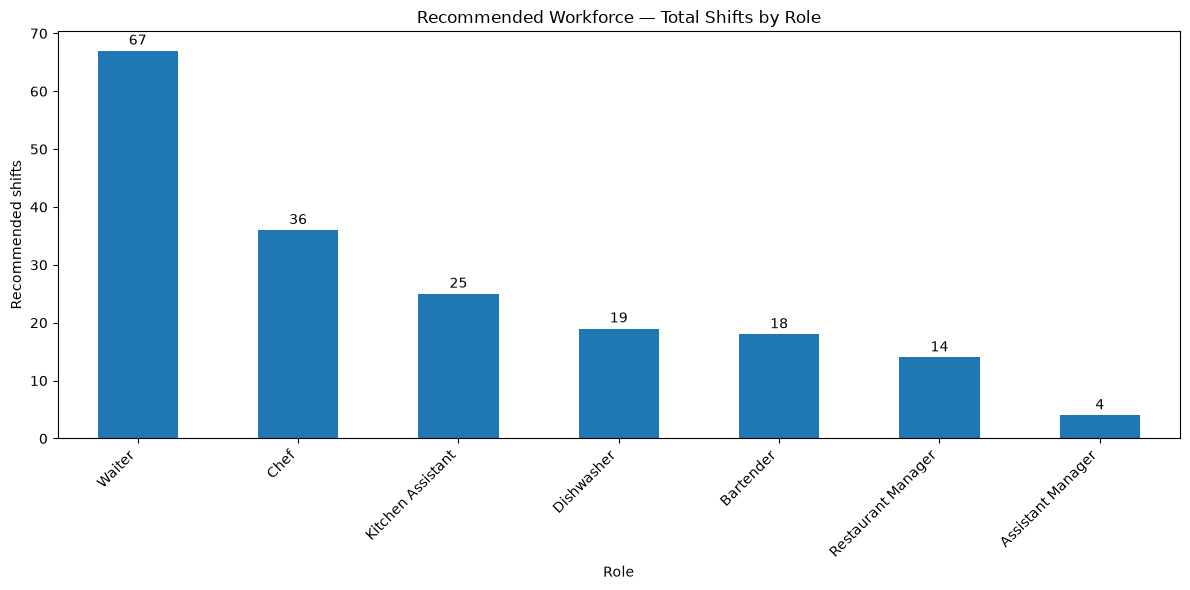

In [45]:
# ============================================================
# Chart: RECOMMENDED STAFFING BY ROLE
# ============================================================

plt.figure(figsize=(12, 6))

bar=(
    recommended_by_role
    .set_index("role")["shifts"]
    .sort_values(ascending=False)
    .plot(kind="bar")
)

plt.title( "Recommended Workforce — Total Shifts by Role" )
bar.bar_label(bar.containers[0], padding=2)
plt.xlabel("Role")
plt.ylabel("Recommended shifts")

plt.xticks( rotation=45, ha="right" )

plt.tight_layout()
plt.show()

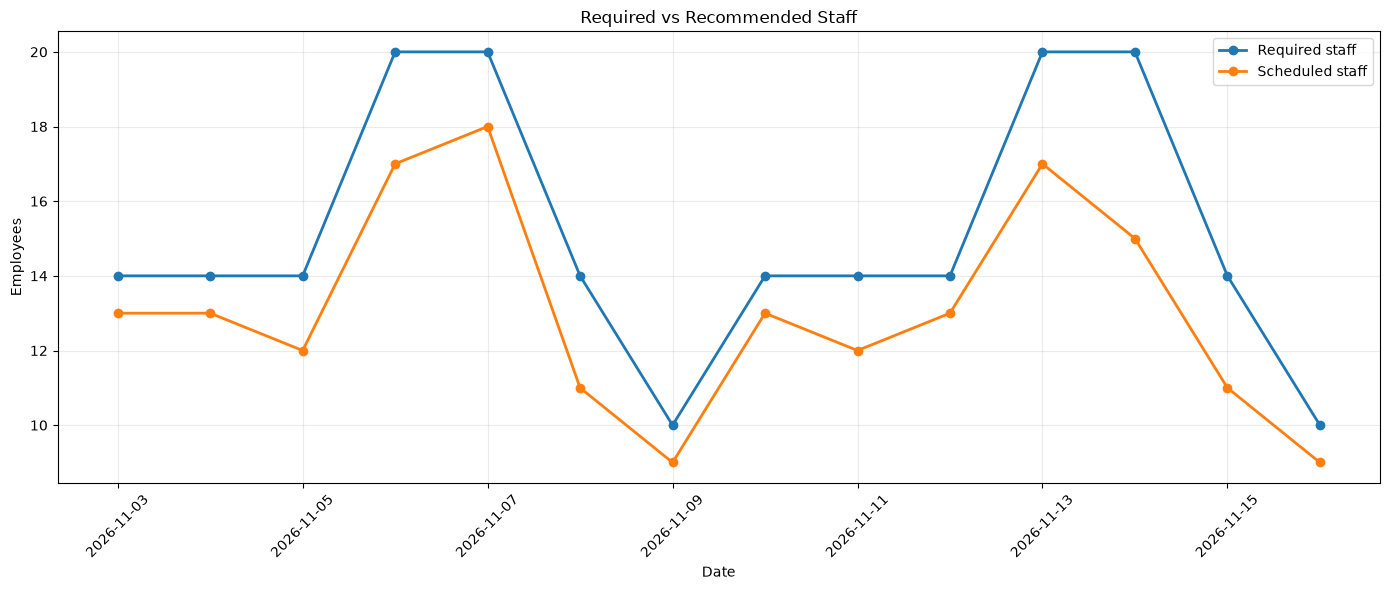

In [46]:
# ============================================================
# DAILY STAFFING REQUIREMENT
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    workforce_forecast["date"],
    workforce_forecast["required_staff"],
    marker="o",
    linewidth=2,
    label="Required staff"
)

plt.plot(
    workforce_forecast["date"],
    workforce_forecast["scheduled_employees"],
    marker="o",
    linewidth=2,
    label="Scheduled staff"
)

plt.title(
    "Required vs Recommended Staff"
)

plt.xlabel("Date")
plt.ylabel("Employees")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

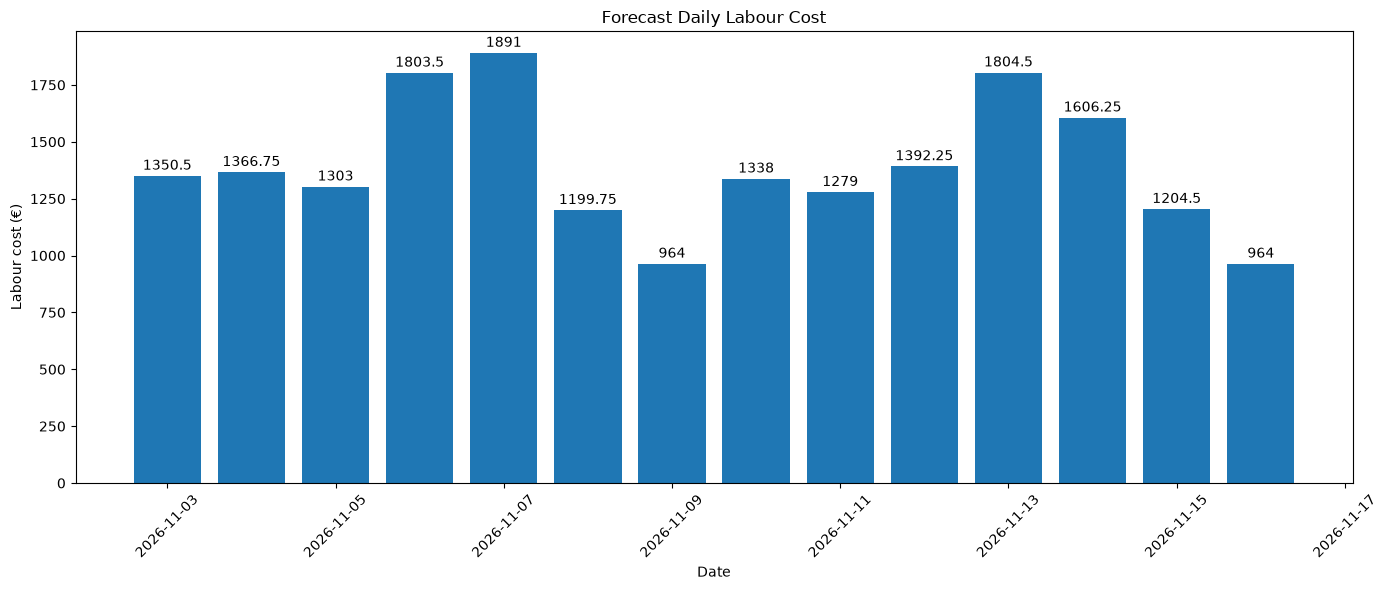

In [47]:
# ============================================================
# DAILY FORECAST LABOUR COST
# ============================================================

plt.figure(figsize=(14, 6))

plt.bar(
    workforce_forecast["date"],
    workforce_forecast["labour_cost"]
)

plt.title(
    "Forecast Daily Labour Cost"
)
plt.bar_label(plt.gca().containers[0], label_type="edge", padding=2)
plt.xlabel("Date")
plt.ylabel("Labour cost (€)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

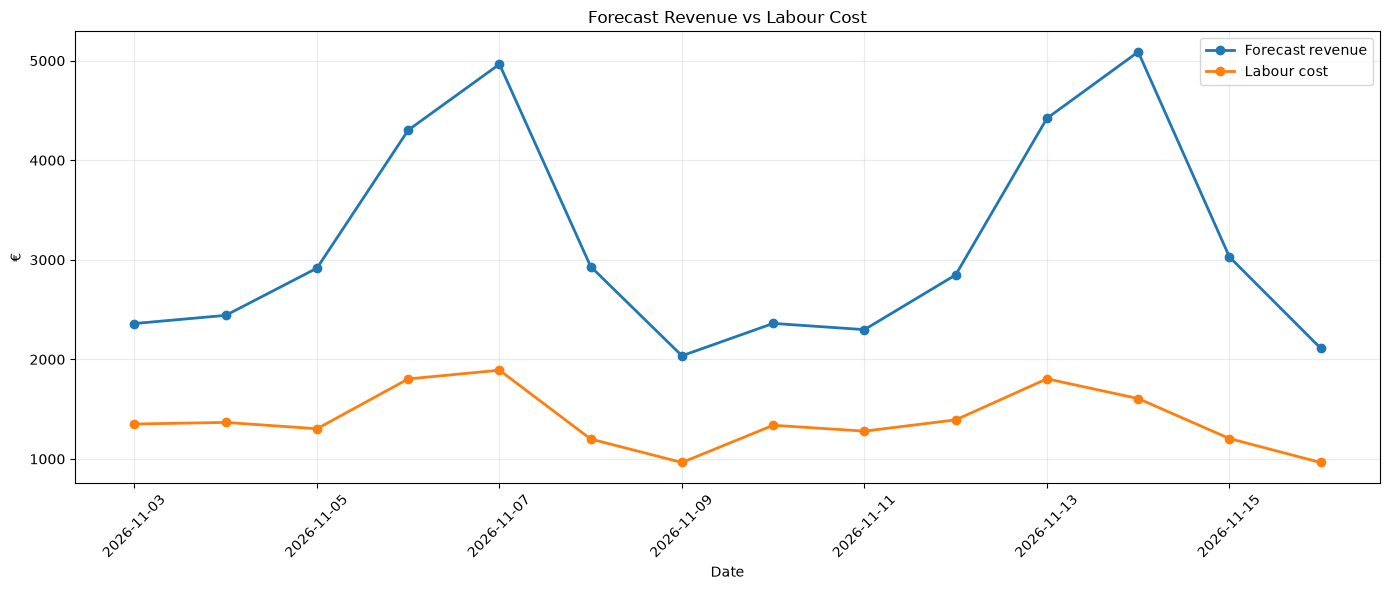

In [48]:
# ============================================================
# LABOUR COST VS FORECAST REVENUE
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    workforce_forecast["date"],
    workforce_forecast["forecast_revenue"],
    marker="o",
    linewidth=2,
    label="Forecast revenue"
)

plt.plot(
    workforce_forecast["date"],
    workforce_forecast["labour_cost"],
    marker="o",
    linewidth=2,
    label="Labour cost"
)

plt.title(
    "Forecast Revenue vs Labour Cost"
)

plt.xlabel("Date")
plt.ylabel("€")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [49]:
# ============================================================
# UNDER-COVERED SHIFTS
# ============================================================

under_covered = (
    staffing_coverage[
        staffing_coverage["shortfall"] > 0
    ]
    .sort_values(
        ["date", "shortfall"],
        ascending=[True, False]
    )
)

display(
    under_covered
)

,date,expected_orders,demand_tier,role,shift_type,required,assigned,shortfall,coverage_status
2,2026-11-03,65,Standard,Chef,Dinner,2,1.00,1.00,Under-covered
16,2026-11-04,67,Standard,Waiter,Dinner,3,2.00,1.00,Under-covered
24,2026-11-05,80,Standard,Kitchen Assistant,Dinner,1,0.00,1.00,Under-covered
29,2026-11-05,80,Standard,Dishwasher,Dinner,1,0.00,1.00,Under-covered
35,2026-11-06,118,High,Kitchen Assistant,Dinner,2,0.00,2.00,Under-covered
37,2026-11-06,118,High,Waiter,Dinner,5,4.00,1.00,Under-covered
48,2026-11-07,136,High,Waiter,Dinner,5,4.00,1.00,Under-covered
51,2026-11-07,136,High,Dishwasher,Dinner,1,0.00,1.00,Under-covered
58,2026-11-08,81,Standard,Waiter,Dinner,3,1.00,2.00,Under-covered
61,2026-11-08,81,Standard,Dishwasher,Dinner,1,0.00,1.00,Under-covered


In [50]:
# ============================================================
# HIGHEST LABOUR-COST DAYS
# ============================================================

highest_cost_days = (
    workforce_forecast[
        [
            "date",
            "expected_orders",
            "demand_tier",
            "scheduled_employees",
            "labour_hours",
            "labour_cost",
            "labour_cost_pct_revenue"
        ]
    ]
    .sort_values(
        "labour_cost",
        ascending=False
    )
)

display(
    highest_cost_days.head(10).round(2)
)

/var/folders/lk/_pf4928d6_x99xld7btjlldc0000gn/T/ipykernel_4499/3343181838.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  highest_cost_days.head(10).round(2)


,date,expected_orders,demand_tier,scheduled_employees,labour_hours,labour_cost,labour_cost_pct_revenue
4,2026-11-07,136,High,18,112.50,"1,891.00",38.09
10,2026-11-13,121,High,17,106.00,"1,804.50",40.81
3,2026-11-06,118,High,17,106.00,"1,803.50",41.92
11,2026-11-14,140,High,15,93.00,"1,606.25",31.57
9,2026-11-12,78,Standard,13,81.00,"1,392.25",48.87
1,2026-11-04,67,Standard,13,81.00,"1,366.75",55.97
0,2026-11-03,65,Standard,13,81.00,"1,350.50",57.23
7,2026-11-10,65,Standard,13,81.00,"1,338.00",56.67
2,2026-11-05,80,Standard,12,74.50,"1,303.00",44.68
8,2026-11-11,63,Standard,12,74.50,"1,279.00",55.64


In [51]:
# ============================================================
# RECOMMENDED EMPLOYEE WORKLOAD
# ============================================================

employee_workload = (
    recommended_roster
    .groupby(
        [
            "employee_id",
            "employee_name",
            "role",
            "employment_type"
        ]
    )
    .agg(
        shifts=("date", "count"),
        total_hours=("hours", "sum"),
        labour_cost=("labour_cost", "sum")
    )
    .reset_index()
)

employee_workload = employee_workload.merge(
    employees[
        [
            "employee_id",
            "weekly_hour_cap"
        ]
    ],
    on="employee_id",
    how="left"
)

display(
    employee_workload
    .sort_values(
        "total_hours",
        ascending=False
    )
    .round(2)
)

,employee_id,employee_name,role,employment_type,shifts,total_hours,labour_cost,weekly_hour_cap
5,E006,Anna Wagner,Chef,Full-time,10,63.00,"1,291.50",40.00
6,E007,Felix Nowak,Chef,Full-time,10,60.00,"1,230.00",40.00
12,E015,Carla Weber,Waiter,Full-time,10,59.00,914.50,40.00
13,E016,Laura Jung,Waiter,Full-time,10,58.00,870.00,40.00
4,E005,Katarina Fischer,Chef,Full-time,10,58.00,"1,189.00",40.00
17,E021,Piotr Huber,Waiter,Part-time,9,57.50,833.75,30.00
16,E019,Laura Meyer,Waiter,Part-time,9,56.50,847.50,30.00
25,E029,Felix Schulz,Dishwasher,Part-time,9,56.50,791.00,30.00
0,E001,Clara Krause,Restaurant Manager,Full-time,7,56.00,"1,400.00",40.00
1,E002,Piotr Lange,Restaurant Manager,Full-time,7,56.00,"1,372.00",40.00


In [52]:
# ============================================================
# FORECAST WEEKLY HOURS CHECK
# ============================================================

recommended_roster["iso_year"] = (
    recommended_roster["date"]
    .dt.isocalendar()
    .year
)

recommended_roster["iso_week"] = (
    recommended_roster["date"]
    .dt.isocalendar()
    .week
)

forecast_weekly_hours = (
    recommended_roster
    .groupby(
        [
            "employee_id",
            "employee_name",
            "employment_type",
            "iso_year",
            "iso_week"
        ]
    )
    .agg(
        hours=("hours", "sum")
    )
    .reset_index()
)

forecast_weekly_hours["weekly_cap"] = (
    forecast_weekly_hours["employment_type"]
    .map(WEEKLY_HOUR_CAP)
)

forecast_weekly_hours["within_limit"] = (
    forecast_weekly_hours["hours"]
    <= forecast_weekly_hours["weekly_cap"]
)

display(
    forecast_weekly_hours.round(2)
)

,employee_id,employee_name,employment_type,iso_year,iso_week,hours,weekly_cap,within_limit
0,E001,Clara Krause,Full-time,2026,45,24.00,40.00,True
1,E001,Clara Krause,Full-time,2026,46,32.00,40.00,True
2,E002,Piotr Lange,Full-time,2026,45,24.00,40.00,True
3,E002,Piotr Lange,Full-time,2026,46,24.00,40.00,True
4,E002,Piotr Lange,Full-time,2026,47,8.00,40.00,True
...,...,...,...,...,...,...,...,...
56,E028,Nina Schmidt,Part-time,2026,45,27.50,30.00,True
57,E028,Nina Schmidt,Part-time,2026,46,27.50,30.00,True
58,E029,Felix Schulz,Part-time,2026,45,25.00,30.00,True
59,E029,Felix Schulz,Part-time,2026,46,25.00,30.00,True


In [53]:
# ============================================================
# FINAL WORKFORCE CONSTRAINT CHECKS
# ============================================================

roster_checks = recommended_roster.copy()
roster_checks["weekday_num"] = roster_checks["date"].dt.dayofweek + 1

roster_checks = roster_checks.merge(
    employees[["employee_id", "employment_start", "employment_end"]],
    on="employee_id",
    how="left",
    validate="many_to_one"
)

roster_checks = roster_checks.merge(
    availability[
        ["employee_id", "day_of_week_num", "availability_status", "max_hours"]
    ],
    left_on=["employee_id", "weekday_num"],
    right_on=["employee_id", "day_of_week_num"],
    how="left",
    validate="many_to_one"
)

roster_checks["expected_shift_hours"] = (
    roster_checks["shift_type"].map(
        {shift: info["hours"] for shift, info in SHIFT_DEFINITIONS.items()}
    )
)

checks = {
    "No negative labour costs":
        (recommended_roster["labour_cost"] >= 0).all(),

    "All scheduled employees exist":
        recommended_roster["employee_id"].isin(employees["employee_id"]).all(),

    "Weekly hours within contract limits":
        forecast_weekly_hours["within_limit"].all(),

    "Employees are available for assigned weekdays and shift hours":
        (
            roster_checks["availability_status"].notna()
            & roster_checks["availability_status"].ne("Unavailable")
            & roster_checks["max_hours"].ge(roster_checks["hours"])
        ).all(),

    "Employees are within their employment dates":
        (
            roster_checks["date"].ge(roster_checks["employment_start"])
            & (
                roster_checks["employment_end"].isna()
                | roster_checks["date"].le(roster_checks["employment_end"])
            )
        ).all(),

    "No employee is scheduled more than once per day":
        ~recommended_roster.duplicated(["date", "employee_id"]).any(),

    "Daily hours do not exceed 10 hours per employee":
        (
            recommended_roster.groupby(["date", "employee_id"])["hours"]
            .sum()
            .le(MAX_DAILY_HOURS)
            .all()
        ),

    "Assigned hours match the defined shift lengths":
        roster_checks["hours"].eq(roster_checks["expected_shift_hours"]).all(),

    "Gap log reconciles to total coverage shortfall":
        (
            (int(staffing_gaps["unfilled"].sum()) if not staffing_gaps.empty else 0)
            == int(staffing_coverage["shortfall"].sum())
        ),

    "Labour cost equals shift hours multiplied by hourly cost":
        np.isclose(
            recommended_roster["labour_cost"],
            recommended_roster["hours"] * recommended_roster["hourly_cost"]
        ).all()
}

constraint_results = pd.DataFrame({
    "Check": list(checks.keys()),
    "Passed": list(checks.values())
})

display(constraint_results)

if not constraint_results["Passed"].all():
    failed_checks = constraint_results.loc[~constraint_results["Passed"], "Check"].tolist()
    raise AssertionError(f"Workforce constraint checks failed: {failed_checks}")


,Check,Passed
0,No negative labour costs,True
1,All scheduled employees exist,True
2,Weekly hours within contract limits,True
3,Employees are available for assigned weekdays ...,True
4,Employees are within their employment dates,True
5,No employee is scheduled more than once per day,True
6,Daily hours do not exceed 10 hours per employee,True
7,Assigned hours match the defined shift lengths,True
8,Gap log reconciles to total coverage shortfall,True
9,Labour cost equals shift hours multiplied by h...,True


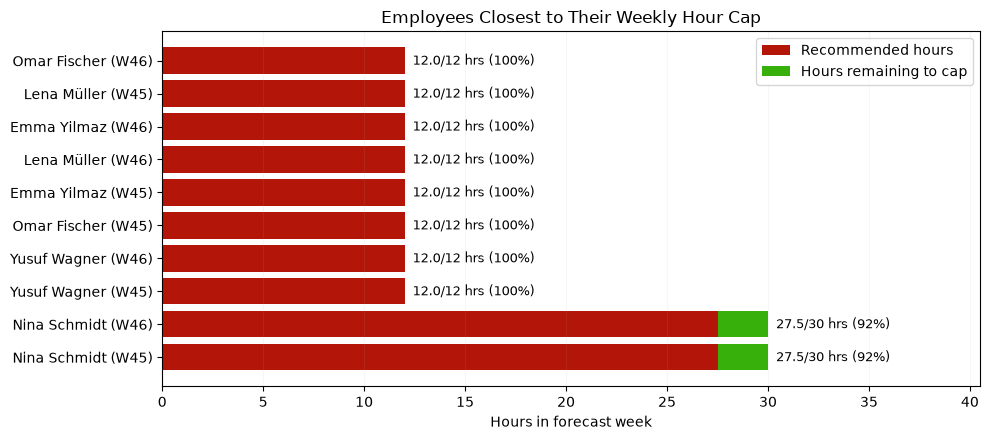

In [54]:
# ============================================================
# EMPLOYEE HOURS VS WEEKLY CONTRACT CAP
# ============================================================

roster_hours = recommended_roster.copy()

roster_hours["iso_year"] = (
    roster_hours["date"].dt.isocalendar().year.astype(int)
)

roster_hours["iso_week"] = (
    roster_hours["date"].dt.isocalendar().week.astype(int)
)

employee_weekly_hours = (
    roster_hours
    .groupby(
        [
            "employee_id",
            "employee_name",
            "employment_type",
            "iso_year",
            "iso_week"
        ],
        as_index=False
    )
    .agg(hours=("hours", "sum"))
)

employee_weekly_hours["weekly_cap"] = (
    employee_weekly_hours["employment_type"]
    .map(WEEKLY_HOUR_CAP)
)

employee_weekly_hours["hours_remaining"] = (
    employee_weekly_hours["weekly_cap"]
    - employee_weekly_hours["hours"]
)

employee_weekly_hours["cap_used_pct"] = (
    employee_weekly_hours["hours"]
    / employee_weekly_hours["weekly_cap"]
    * 100
)

# Show the 10 employee-weeks closest to their weekly cap
closest_to_cap = (
    employee_weekly_hours
    .sort_values("cap_used_pct", ascending=False)
    .head(10)
    .sort_values("cap_used_pct")
    .copy()
)

if closest_to_cap.empty:
    print("No roster assignments available to chart.")
else:
    closest_to_cap["employee_week"] = (
        closest_to_cap["employee_name"]
        + " (W"
        + closest_to_cap["iso_week"].astype(str)
        + ")"
    )

    fig, ax = plt.subplots(
        figsize=(10, max(4, len(closest_to_cap) * 0.45))
    )

    ax.barh(
        closest_to_cap["employee_week"],
        closest_to_cap["hours"],
        label="Recommended hours",
        color="#B31608"
    )

    ax.barh(
        closest_to_cap["employee_week"],
        closest_to_cap["hours_remaining"],
        left=closest_to_cap["hours"],
        label="Hours remaining to cap",
        color="#37b00b"
    )

    for y, (_, row) in enumerate(closest_to_cap.iterrows()):
        ax.text(
            row["weekly_cap"] + 0.4,
            y,
            f'{row["hours"]:.1f}/{row["weekly_cap"]:.0f} hrs '
            f'({row["cap_used_pct"]:.0f}%)',
            va="center",
            fontsize=9
        )

    ax.set_title("Employees Closest to Their Weekly Hour Cap")
    ax.set_xlabel("Hours in forecast week")
    ax.set_ylabel("")
    ax.set_xlim(
        0,
        closest_to_cap["weekly_cap"].max() * 1.35
    )
    ax.legend(loc="upper right")
    ax.grid(axis="x", alpha=0.1)

    plt.tight_layout()
    plt.show()

In [55]:
# ============================================================
# FINAL WORKFORCE INTELLIGENCE SUMMARY
# ============================================================

print("=" * 65)
print("RESTRODINE — WORKFORCE INTELLIGENCE")
print("=" * 65)

print(
    f"\nPlanning horizon: "
    f"{workforce_forecast['date'].min().date()} "
    f"→ "
    f"{workforce_forecast['date'].max().date()}"
)

print(
    f"\nExpected orders: "
    f"{forecast_total_orders:,.0f}"
)

print(
    f"Forecast revenue: "
    f"€{forecast_total_revenue:,.2f}"
)

print(
    f"Scheduled labour hours: "
    f"{forecast_labour_hours:,.1f}"
)

print(
    f"Estimated labour cost: "
    f"€{forecast_labour_cost:,.2f}"
)

print(
    f"Labour cost / revenue: "
    f"{forecast_labour_cost_pct:.2f}%"
)

print(
    f"Orders / labour hour: "
    f"{forecast_orders_per_labour_hour:.2f}"
)

print(
    f"Labour cost / order: "
    f"€{forecast_labour_cost_per_order:.2f}"
)

print("=" * 65)

RESTRODINE — WORKFORCE INTELLIGENCE

Planning horizon: 2026-11-03 → 2026-11-16

Expected orders: 1,211
Forecast revenue: €44,111.13
Scheduled labour hours: 1,140.5
Estimated labour cost: €19,467.00
Labour cost / revenue: 44.13%
Orders / labour hour: 1.06
Labour cost / order: €16.08


In [56]:
# ============================================================
# FINAL RECOMMENDED ROSTER
# ============================================================

final_roster = (
    recommended_roster[
        [
            "date",
            "employee_id",
            "employee_name",
            "role",
            "employment_type",
            "shift_type",
            "start_time",
            "end_time",
            "hours",
            "hourly_cost",
            "labour_cost"
        ]
    ]
    .sort_values(
        [
            "date",
            "start_time",
            "role",
            "employee_name"
        ]
    )
    .reset_index(drop=True)
)

display(
    final_roster.round(2)
)

/var/folders/lk/_pf4928d6_x99xld7btjlldc0000gn/T/ipykernel_4499/2491895968.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  final_roster.round(2)


,date,employee_id,employee_name,role,employment_type,shift_type,start_time,end_time,hours,hourly_cost,labour_cost
0,2026-11-03,E006,Anna Wagner,Chef,Full-time,Lunch,10:30,16:00,5.50,20.50,112.75
1,2026-11-03,E028,Nina Schmidt,Dishwasher,Part-time,Lunch,10:30,16:00,5.50,14.00,77.00
2,2026-11-03,E010,Yusuf Jung,Kitchen Assistant,Part-time,Lunch,10:30,16:00,5.50,15.00,82.50
3,2026-11-03,E015,Carla Weber,Waiter,Full-time,Lunch,10:30,16:00,5.50,15.50,85.25
4,2026-11-03,E017,Tom Richter,Waiter,Full-time,Lunch,10:30,16:00,5.50,15.50,85.25
...,...,...,...,...,...,...,...,...,...,...,...
178,2026-11-16,E026,Ayşe Meier,Bartender,Part-time,Dinner,16:30,23:00,6.50,16.50,107.25
179,2026-11-16,E029,Felix Schulz,Dishwasher,Part-time,Dinner,16:30,23:00,6.50,14.00,91.00
180,2026-11-16,E010,Yusuf Jung,Kitchen Assistant,Part-time,Dinner,16:30,23:00,6.50,15.00,97.50
181,2026-11-16,E019,Laura Meyer,Waiter,Part-time,Dinner,16:30,23:00,6.50,15.00,97.50


In [57]:
# ============================================================
# EXECUTIVE WORKFORCE TABLE
# ============================================================

executive_workforce = workforce_forecast[
    [
        "date",
        "expected_orders",
        "demand_tier",
        "required_staff",
        "scheduled_employees",
        "labour_hours",
        "labour_cost",
        "labour_cost_pct_revenue"
    ]
].copy()

executive_workforce["date"] = (
    executive_workforce["date"]
    .dt.strftime("%Y-%m-%d")
)

display(
    executive_workforce.round(2)
)

,date,expected_orders,demand_tier,required_staff,scheduled_employees,labour_hours,labour_cost,labour_cost_pct_revenue
0,2026-11-03,65,Standard,14,13,81.00,"1,350.50",57.23
1,2026-11-04,67,Standard,14,13,81.00,"1,366.75",55.97
2,2026-11-05,80,Standard,14,12,74.50,"1,303.00",44.68
3,2026-11-06,118,High,20,17,106.00,"1,803.50",41.92
4,2026-11-07,136,High,20,18,112.50,"1,891.00",38.09
5,2026-11-08,81,Standard,14,11,68.00,"1,199.75",40.92
6,2026-11-09,56,Low,10,9,57.00,964.00,47.35
7,2026-11-10,65,Standard,14,13,81.00,"1,338.00",56.67
8,2026-11-11,63,Standard,14,12,74.50,"1,279.00",55.64
9,2026-11-12,78,Standard,14,13,81.00,"1,392.25",48.87


# 5. Required vs. scheduled positions and labour cost

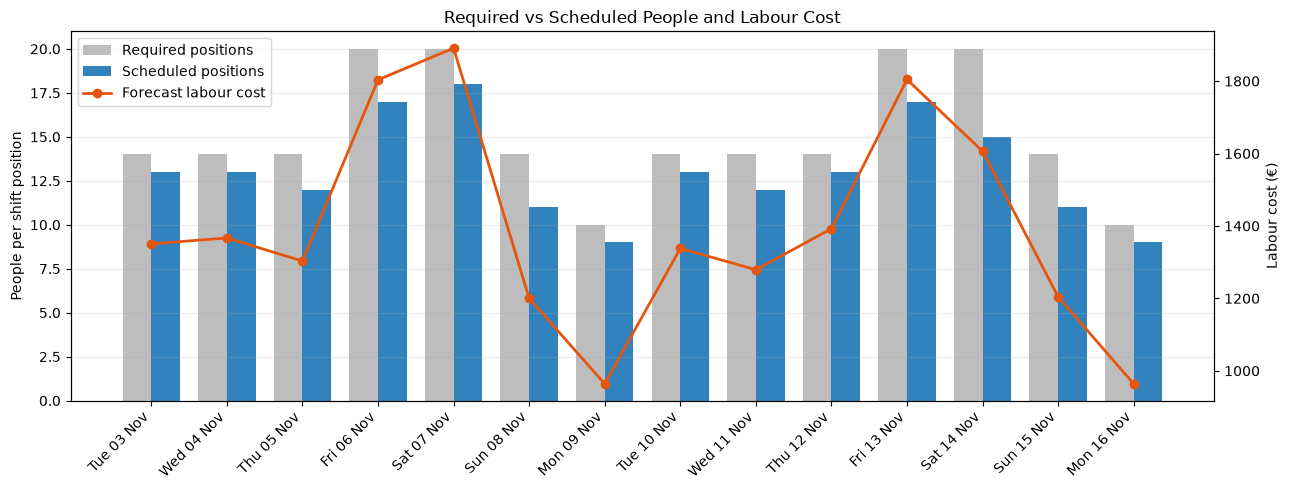

In [58]:
# ============================================================
# REQUIRED VS SCHEDULED PEOPLE AND LABOUR COST
# ============================================================

scheduled_positions = (
    recommended_roster
    .groupby("date")
    .size()
    .rename("scheduled_positions")
)

chart_data = (
    workforce_forecast
    .set_index("date")
    .join(scheduled_positions)
)

chart_data["scheduled_positions"] = (
    chart_data["scheduled_positions"]
    .fillna(0)
)

x = np.arange(len(chart_data))
bar_width = 0.38

fig, ax = plt.subplots(figsize=(13, 5))

ax.bar(
    x - bar_width / 2,
    chart_data["required_staff"],
    bar_width,
    label="Required positions",
    color="#bdbdbd"
)

ax.bar(
    x + bar_width / 2,
    chart_data["scheduled_positions"],
    bar_width,
    label="Scheduled positions",
    color="#3182bd"
)

ax.set_xticks(x)
ax.set_xticklabels(
    chart_data.index.strftime("%a %d %b"),
    rotation=45,
    ha="right"
)
ax.set_ylabel("People per shift position")
ax.set_title("Required vs Scheduled People and Labour Cost")
ax.grid(axis="y", alpha=0.25)

ax_cost = ax.twinx()
ax_cost.plot(
    x,
    chart_data["labour_cost"],
    color="#e6550d",
    marker="o",
    linewidth=2,
    label="Forecast labour cost"
)
ax_cost.set_ylabel("Labour cost (€)")

handles, labels = ax.get_legend_handles_labels()
cost_handles, cost_labels = ax_cost.get_legend_handles_labels()
ax.legend(
    handles + cost_handles,
    labels + cost_labels,
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [66]:
# ============================================================
# 14-DAY WORKFORCE OVERVIEW
# ============================================================

import plotly.express as px

overview = (
    staffing_coverage
    .groupby("date", as_index=False)
    .agg(
        required_positions=("required", "sum"),
        scheduled_positions=("assigned", "sum"),
        unfilled_positions=("shortfall", "sum")
    )
    .merge(
        workforce_forecast[
            ["date", "labour_cost", "forecast_revenue",
             "labour_cost_pct_revenue"]
        ],
        on="date",
        how="left"
    )
    .sort_values("date")
)

overview_long = overview.melt(
    id_vars=["date"],
    value_vars=[
        "required_positions",
        "scheduled_positions",
        "unfilled_positions"
    ],
    var_name="measure",
    value_name="positions"
)

measure_labels = {
    "required_positions": "Required",
    "scheduled_positions": "Assigned",
    "unfilled_positions": "Unfilled"
}

overview_long["measure"] = overview_long["measure"].map(measure_labels)

fig_overview = px.bar(
    overview_long,
    x="date",
    y="positions",
    color="measure",
    barmode="group",
    color_discrete_map={
        "Required": "#9aa0a6",
        "Assigned": "#3182bd",
        "Unfilled": "#e45756"
    },
    hover_data={"date": "|%a %d %b", "positions": True},
    labels={
        "date": "Forecast date",
        "positions": "Shift positions",
        "measure": ""
    },
    title="Workforce Coverage Across the Forecast"
)

fig_overview.update_layout(
    height=430,
    legend_title_text="",
    hovermode="x unified"
)

fig_overview.update_xaxes(
    tickformat="%a %d %b",
    tickangle=-35
)

fig_overview.update_yaxes(dtick=2)

fig_overview.show()

# Keep the detailed daily figures available in a compact table.
display(
    overview[
        [
            "date",
            "required_positions",
            "scheduled_positions",
            "unfilled_positions",
            "labour_cost",
            "labour_cost_pct_revenue"
        ]
    ].round(2)
)

/var/folders/lk/_pf4928d6_x99xld7btjlldc0000gn/T/ipykernel_4499/1355729345.py:91: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,date,required_positions,scheduled_positions,unfilled_positions,labour_cost,labour_cost_pct_revenue
0,2026-11-03,14,13.00,1.00,"1,350.50",57.23
1,2026-11-04,14,13.00,1.00,"1,366.75",55.97
2,2026-11-05,14,12.00,2.00,"1,303.00",44.68
3,2026-11-06,20,17.00,3.00,"1,803.50",41.92
4,2026-11-07,20,18.00,2.00,"1,891.00",38.09
5,2026-11-08,14,11.00,3.00,"1,199.75",40.92
6,2026-11-09,10,9.00,1.00,964.00,47.35
7,2026-11-10,14,13.00,1.00,"1,338.00",56.67
8,2026-11-11,14,12.00,2.00,"1,279.00",55.64
9,2026-11-12,14,13.00,1.00,"1,392.25",48.87


# 6. Required staffing by role and date

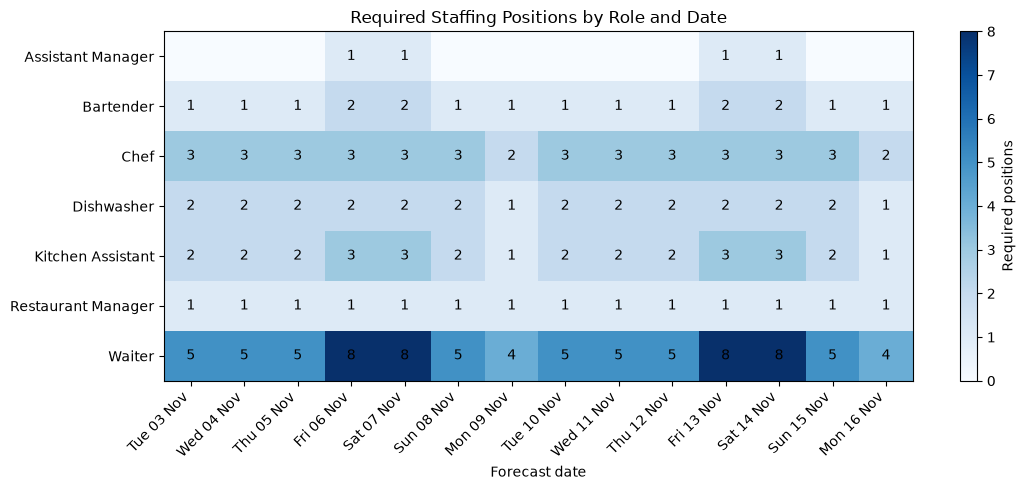

In [60]:
# ============================================================
# REQUIRED POSITIONS BY ROLE AND DATE
# ============================================================

required_role_day = (
    forecast_staffing
    .pivot_table(
        index="role",
        columns="date",
        values="required",
        aggfunc="sum",
        fill_value=0
    )
)

fig, ax = plt.subplots(
    figsize=(max(10, len(required_role_day.columns) * 0.8), 5)
)

image = ax.imshow(
    required_role_day.values,
    aspect="auto",
    cmap="Blues"
)

ax.set_yticks(np.arange(len(required_role_day.index)))
ax.set_yticklabels(required_role_day.index)

ax.set_xticks(np.arange(len(required_role_day.columns)))
ax.set_xticklabels(
    required_role_day.columns.strftime("%a %d %b"),
    rotation=45,
    ha="right"
)

for row in range(required_role_day.shape[0]):
    for col in range(required_role_day.shape[1]):
        value = required_role_day.iloc[row, col]
        if value > 0:
            ax.text(col, row, int(value), ha="center", va="center")

ax.set_title("Required Staffing Positions by Role and Date")
ax.set_xlabel("Forecast date")
fig.colorbar(image, ax=ax, label="Required positions")
plt.tight_layout()
plt.show()

# 7. Recommended roster calendar

In [61]:
# ============================================================
# RECOMMENDED ROSTER CALENDAR WITH SHIFT TIMES
# ============================================================

roster_calendar_data = recommended_roster.copy()

# Show shift name plus its scheduled time.
roster_calendar_data["shift_display"] = (
    roster_calendar_data["shift_type"]
    + "\n"
    + roster_calendar_data["start_time"]
    + "–"
    + roster_calendar_data["end_time"]
)

roster_calendar = (
    roster_calendar_data
    .pivot_table(
        index=["role", "employee_name"],
        columns="date",
        values="shift_display",
        aggfunc="first"
    )
    .fillna("—")
    .reset_index()
    .rename(columns={
        "role": "Role",
        "employee_name": "Employee"
    })
)

roster_calendar.columns = [
    column.strftime("%a %d %b")
    if isinstance(column, pd.Timestamp)
    else column
    for column in roster_calendar.columns
]

shift_colors = {
    "Lunch": "background-color: #d9edf7; color: #174a65;",
    "Dinner": "background-color: #fce5cd; color: #7f3b08;",
    "Full": "background-color: #e4dfec; color: #49365f;"
}

def style_roster_shift(cell):
    for shift_name, style in shift_colors.items():
        if isinstance(cell, str) and cell.startswith(shift_name):
            return style
    return ""

styled_roster_calendar = (
    roster_calendar.style
    .map(style_roster_shift)
    .set_properties(**{
        "text-align": "center",
        "min-width": "105px",
        "white-space": "pre-line"
    })
    .set_properties(
        subset=["Role", "Employee"],
        **{
            "text-align": "left",
            "min-width": "150px"
        }
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#34495e"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center")
            ]
        },
        {
            "selector": "td",
            "props": [("padding", "7px")]
        }
    ])
    .hide(axis="index")
)

display(styled_roster_calendar)

Role,Employee,Tue 03 Nov,Wed 04 Nov,Thu 05 Nov,Fri 06 Nov,Sat 07 Nov,Sun 08 Nov,Mon 09 Nov,Tue 10 Nov,Wed 11 Nov,Thu 12 Nov,Fri 13 Nov,Sat 14 Nov,Sun 15 Nov,Mon 16 Nov
Assistant Manager,Carla Schmitt,—,—,—,Dinner 16:30–23:00,—,—,—,—,—,—,Dinner 16:30–23:00,—,—,—
Assistant Manager,Giulia Kowalski,—,—,—,—,Dinner 16:30–23:00,—,—,—,—,—,—,Dinner 16:30–23:00,—,—
Bartender,Ayşe Meier,Dinner 16:30–23:00,—,—,Dinner 16:30–23:00,—,—,Dinner 16:30–23:00,Dinner 16:30–23:00,—,—,—,—,—,Dinner 16:30–23:00
Bartender,Felix Klein,—,—,—,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,—,—,—,—,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,—
Bartender,Lisa Werner,—,Dinner 16:30–23:00,Dinner 16:30–23:00,—,Dinner 16:30–23:00,—,—,—,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,—,—
Chef,Anna Wagner,Lunch 10:30–16:00,—,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,—,Lunch 10:30–16:00,—,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,—
Chef,David Kowalski,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,—,—,—,—,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,—,—,—,—
Chef,Felix Nowak,—,Dinner 16:30–23:00,—,Lunch 10:30–16:00,Lunch 10:30–16:00,Lunch 10:30–16:00,Lunch 10:30–16:00,—,Dinner 16:30–23:00,—,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,Lunch 10:30–16:00
Chef,Katarina Fischer,—,Lunch 10:30–16:00,Lunch 10:30–16:00,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,—,—,Lunch 10:30–16:00,Lunch 10:30–16:00,Lunch 10:30–16:00,Lunch 10:30–16:00,Lunch 10:30–16:00,—
Dishwasher,Felix Schulz,Dinner 16:30–23:00,Dinner 16:30–23:00,Lunch 10:30–16:00,Dinner 16:30–23:00,—,—,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,Lunch 10:30–16:00,—,—,—,Dinner 16:30–23:00


In [62]:
# ============================================================
# WEEKLY ROSTER VIEW
# ============================================================

# Choose 1 for the first seven forecast dates, 2 for the next seven.
selected_week = 1 # or 2 for the next seven forecast dates, etc.

all_forecast_dates = pd.DatetimeIndex(
    sorted(revenue_forecast["date"].drop_duplicates())
)

week_start_index = (selected_week - 1) * 7
week_dates = all_forecast_dates[week_start_index:week_start_index + 7]

if len(week_dates) == 0:
    print("That week number is outside the forecast period.")
else:
    week_roster = recommended_roster.loc[
        recommended_roster["date"].isin(week_dates)
    ].copy()

    week_roster["shift_display"] = (
        week_roster["shift_type"]
        + "\n"
        + week_roster["start_time"]
        + "–"
        + week_roster["end_time"]
    )

    roster_week_table = (
        week_roster
        .pivot_table(
            index=["role", "employee_name"],
            columns="date",
            values="shift_display",
            aggfunc="first"
        )
        .reindex(columns=week_dates)
        .fillna("—")
        .reset_index()
        .rename(columns={
            "role": "Role",
            "employee_name": "Employee"
        })
    )

    roster_week_table.columns = [
        column.strftime("%a %d %b")
        if isinstance(column, pd.Timestamp)
        else column
        for column in roster_week_table.columns
    ]

    shift_colors = {
        "Lunch": "background-color: #d9edf7; color: #174a65;",
        "Dinner": "background-color: #fce5cd; color: #7f3b08;",
        "Full": "background-color: #e4dfec; color: #49365f;"
    }

    def style_weekly_shift(value):
        if isinstance(value, str):
            for shift_name, style in shift_colors.items():
                if value.startswith(shift_name):
                    return style
        return ""

    styled_week_roster = (
        roster_week_table.style
        .map(style_weekly_shift)
        .set_properties(**{
            "text-align": "center",
            "min-width": "115px",
            "white-space": "pre-line"
        })
        .set_properties(
            subset=["Role", "Employee"],
            **{
                "text-align": "left",
                "min-width": "150px"
            }
        )
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("background-color", "#34495e"),
                    ("color", "white"),
                    ("font-weight", "bold"),
                    ("text-align", "center")
                ]
            },
            {
                "selector": "td",
                "props": [("padding", "7px")]
            }
        ])
        .hide(axis="index")
    )

    print(
        f"Recommended roster: "
        f"{week_dates[0]:%a %d %b} – {week_dates[-1]:%a %d %b}"
    )
    print("Shift colors: Lunch = blue | Dinner = orange | Full = purple")
    display(styled_week_roster)

Recommended roster: Tue 03 Nov – Mon 09 Nov
Shift colors: Lunch = blue | Dinner = orange | Full = purple


Role,Employee,Tue 03 Nov,Wed 04 Nov,Thu 05 Nov,Fri 06 Nov,Sat 07 Nov,Sun 08 Nov,Mon 09 Nov
Assistant Manager,Carla Schmitt,—,—,—,Dinner 16:30–23:00,—,—,—
Assistant Manager,Giulia Kowalski,—,—,—,—,Dinner 16:30–23:00,—,—
Bartender,Ayşe Meier,Dinner 16:30–23:00,—,—,Dinner 16:30–23:00,—,—,Dinner 16:30–23:00
Bartender,Felix Klein,—,—,—,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,—
Bartender,Lisa Werner,—,Dinner 16:30–23:00,Dinner 16:30–23:00,—,Dinner 16:30–23:00,—,—
Chef,Anna Wagner,Lunch 10:30–16:00,—,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,—
Chef,David Kowalski,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,—,—,—,—
Chef,Felix Nowak,—,Dinner 16:30–23:00,—,Lunch 10:30–16:00,Lunch 10:30–16:00,Lunch 10:30–16:00,Lunch 10:30–16:00
Chef,Katarina Fischer,—,Lunch 10:30–16:00,Lunch 10:30–16:00,Dinner 16:30–23:00,Dinner 16:30–23:00,Dinner 16:30–23:00,—
Dishwasher,Felix Schulz,Dinner 16:30–23:00,Dinner 16:30–23:00,Lunch 10:30–16:00,Dinner 16:30–23:00,—,—,Dinner 16:30–23:00


In [63]:
# ============================================================
# SELECTED-DAY ROSTER TIMELINE
# ============================================================

# Change this date to any date in the forecast.
selected_date = pd.Timestamp("2026-11-03")

daily_roster = recommended_roster.loc[
    recommended_roster["date"].dt.normalize() == selected_date.normalize()
].copy()

if daily_roster.empty:
    print(f"No employees were assigned for {selected_date:%A, %d %B %Y}.")
else:
    daily_roster["employee_label"] = (
        daily_roster["role"]
        + " — "
        + daily_roster["employee_name"]
    )

    daily_roster["start_datetime"] = pd.to_datetime(
        daily_roster["date"].dt.strftime("%Y-%m-%d")
        + " "
        + daily_roster["start_time"]
    )

    daily_roster["end_datetime"] = pd.to_datetime(
        daily_roster["date"].dt.strftime("%Y-%m-%d")
        + " "
        + daily_roster["end_time"]
    )

    daily_roster["shift_label"] = (
        daily_roster["shift_type"]
        + "  "
        + daily_roster["start_time"]
        + "–"
        + daily_roster["end_time"]
    )

    employee_order = (
        daily_roster
        .sort_values(["role", "employee_name"])["employee_label"]
        .drop_duplicates()
        .tolist()
    )

    fig_roster = px.timeline(
        daily_roster,
        x_start="start_datetime",
        x_end="end_datetime",
        y="employee_label",
        color="shift_type",
        text="shift_label",
        category_orders={
            "employee_label": employee_order,
            "shift_type": ["Lunch", "Dinner", "Full"]
        },
        color_discrete_map={
            "Lunch": "#3182bd",
            "Dinner": "#f28e2b",
            "Full": "#8064a2"
        },
        hover_data={
            "role": True,
            "employee_name": True,
            "shift_type": True,
            "start_time": True,
            "end_time": True,
            "hours": ":.1f",
            "labour_cost": ":.2f",
            "employee_label": False,
            "shift_label": False,
            "start_datetime": False,
            "end_datetime": False
        },
        labels={
            "employee_label": "Employee",
            "shift_type": "Shift",
            "hours": "Hours",
            "labour_cost": "Labour cost (€)"
        },
        title=f"Recommended Roster — {selected_date:%A, %d %B %Y}"
    )

    fig_roster.update_yaxes(
        autorange="reversed",
        title=""
    )

    fig_roster.update_xaxes(
        tickformat="%H:%M",
        dtick=60 * 60 * 1000,
        title="Shift time"
    )

    fig_roster.update_traces(
        textposition="inside",
        insidetextanchor="middle"
    )

    fig_roster.update_layout(
        height=max(420, 34 * daily_roster["employee_id"].nunique()),
        legend_title_text="",
        margin=dict(l=20, r=20, t=60, b=40)
    )

    fig_roster.show()

    print("Assigned shifts for this day:")
    display(
        daily_roster[
            [
                "employee_name",
                "role",
                "shift_type",
                "start_time",
                "end_time",
                "hours",
                "labour_cost"
            ]
        ]
        .sort_values(["start_time", "role", "employee_name"])
        .round(2)
        .reset_index(drop=True)
    )

# Show uncovered requirements for this date, with their reasons.
daily_gaps = staffing_gaps.loc[
    pd.to_datetime(staffing_gaps["date"]).dt.normalize()
    == selected_date.normalize()
]

print(f"Unfilled positions for {selected_date:%A, %d %B %Y}:")
if daily_gaps.empty:
    print("None — all required positions were assigned.")
else:
    display(
        daily_gaps[
            ["role", "shift_type", "hours", "unfilled", "reason"]
        ].reset_index(drop=True)
    )

Assigned shifts for this day:


,employee_name,role,shift_type,start_time,end_time,hours,labour_cost
0,Anna Wagner,Chef,Lunch,10:30,16:00,5.50,112.75
1,Nina Schmidt,Dishwasher,Lunch,10:30,16:00,5.50,77.00
2,Yusuf Jung,Kitchen Assistant,Lunch,10:30,16:00,5.50,82.50
3,Carla Weber,Waiter,Lunch,10:30,16:00,5.50,85.25
4,Tom Richter,Waiter,Lunch,10:30,16:00,5.50,85.25
5,Piotr Lange,Restaurant Manager,Full,11:30,20:00,8.00,196.00
6,Ayşe Meier,Bartender,Dinner,16:30,23:00,6.50,107.25
7,David Kowalski,Chef,Dinner,16:30,23:00,6.50,136.50
8,Felix Schulz,Dishwasher,Dinner,16:30,23:00,6.50,91.00
9,Leon Meyer,Kitchen Assistant,Dinner,16:30,23:00,6.50,100.75


Unfilled positions for Tuesday, 03 November 2026:


,role,shift_type,hours,unfilled,reason
0,Chef,Dinner,6.50,1,only 1 eligible employee(s) for 2 required pos...


# 8. Save the outputs

In [64]:
# ============================================================
# SAVE WORKFORCE OUTPUTS
# ============================================================

output_dir = OUTPUT_DIR
output_dir.mkdir(parents=True, exist_ok=True)

for output_df in [workforce_forecast, final_roster, staffing_coverage, staffing_gaps]:
    if "date" in output_df.columns:
        output_df["date"] = pd.to_datetime(output_df["date"])

workforce_horizon = workforce_forecast["date"].nunique()
workforce_forecast_path = (
    output_dir / f"workforce_forecast_next_{workforce_horizon}_days.csv"
)
roster_path = output_dir / "recommended_roster.csv"
coverage_path = output_dir / "staffing_coverage.csv"
gaps_path = output_dir / "staffing_gaps.csv"

workforce_forecast.to_csv(workforce_forecast_path, index=False)
final_roster.to_csv(roster_path, index=False)
staffing_coverage.to_csv(coverage_path, index=False)
staffing_gaps.to_csv(gaps_path, index=False)

print("Workforce outputs saved successfully.")
print(f"Workforce forecast: {workforce_forecast_path}")
print(f"Recommended roster: {roster_path}")
print(f"Staffing coverage: {coverage_path}")
print(f"Staffing gaps and reasons: {gaps_path}")
print(
    "Forecast period:",
    workforce_forecast["date"].min().date(),
    "to",
    workforce_forecast["date"].max().date()
)
print("Forecast days:", workforce_horizon)
print("Recommended roster rows:", len(final_roster))
print("Staffing gap rows:", len(staffing_gaps))
print("\nWorkforce forecasting pipeline complete.")


Workforce outputs saved successfully.
Workforce forecast: ../outputs/workforce_forecast_next_14_days.csv
Recommended roster: ../outputs/recommended_roster.csv
Staffing coverage: ../outputs/staffing_coverage.csv
Staffing gaps and reasons: ../outputs/staffing_gaps.csv
Forecast period: 2026-11-03 to 2026-11-16
Forecast days: 14
Recommended roster rows: 183
Staffing gap rows: 21

Workforce forecasting pipeline complete.


In [65]:
# ============================================================
# WORKFORCE INTELLIGENCE — INTERPRETATION
# ============================================================

under_coverage_days = (
    staffing_coverage
    .groupby("date")["shortfall"]
    .sum()
    .gt(0)
    .sum()
)

print(
    "WORKFORCE INTELLIGENCE CONCLUSION"
)
print("-" * 60)

print(
    f"The workforce planning model converts forecast demand "
    f"into staffing requirements across a {FORECAST_HORIZON}-day horizon."
)

print(
    f"\nExpected orders: {forecast_total_orders:,.0f}"
)

print(
    f"Estimated labour cost: €{forecast_labour_cost:,.2f}"
)

print(
    f"Labour cost as a percentage of forecast revenue: "
    f"{forecast_labour_cost_pct:.2f}%"
)

print(
    f"\nDays with staffing coverage shortfalls: "
    f"{under_coverage_days}"
)

print(
    "\nThe recommended roster respects employee availability "
    "and contractual weekly-hour limits where sufficient eligible "
    "employees are available."
)

WORKFORCE INTELLIGENCE CONCLUSION
------------------------------------------------------------
The workforce planning model converts forecast demand into staffing requirements across a 14-day horizon.

Expected orders: 1,211
Estimated labour cost: €19,467.00
Labour cost as a percentage of forecast revenue: 44.13%

Days with staffing coverage shortfalls: 14

The recommended roster respects employee availability and contractual weekly-hour limits where sufficient eligible employees are available.
